# 산불 탐지 프로젝트 · AI Hub 산불 데이터 탐색(EDA)

**데이터** AI Hub 71330 「지역안전재난(산불) 방재의 고도화를 위한 대규모 인공지능 데이터베이스」 공개분 (학습 560,365장 · 검증 69,635장, 라벨 JSON 같은 수)
**목적** 라벨·사진이 믿을 만한지 확인하고, 클래스·촬영 조건·물체 크기·방해 요소(구름·안개/연무·굴뚝연기)·픽셀 특성을 살펴, 전처리와 실험 설계(구름·안개가 오경보를 늘린다는 가설 검증)를 정한다.

### 분석 구성과 데이터 범위

| 절 | 분석 | 처음 안 | 이 노트북의 범위 | 이유 |
|---|---|---|---|---|
| 3 | JSON 라벨과 사진 매칭 · 무결성 (짝, 구조, 열림, 크기 일치, 좌표, 환경 값 형식) | 전체 100% 권장 | **100%** (JSON 63만 개, 사진 63만 장) | 한 장이라도 어긋나면 학습 중 오류나 틀린 정답이 된다. 라벨 읽기와 이미 전수로 열어 둔 결과로 충분해 비용이 작다 |
| 4 | 클래스 개수 · 비율 | 전체 100% | **100%** | 라벨만 읽으면 된다 |
| 5 | 실제 사진 보기 | 1~5% 또는 클래스별 50~100장 | **클래스·조건별 격자 약 180장 (영상 하나에 1장)** | 1~5%는 6천~3만 장이라 노트북에 담을 수 없고, 같은 영상의 이웃 프레임이라 많이 봐도 새로 보이는 것이 적다. 대신 영상·장소가 겹치지 않게 뽑는다 |
| 6 | 이미지 크기 · 해상도 · 파일 크기 | 전체 100% 권장 | **100%** | 실제로 사진을 열어 잰 크기로 본다 |
| 7 | 촬영 조건 · 장소 · 날짜 *(추가)* | – | **100%** | 조건이 클래스와 묶여 있으면 모델이 조건으로 답을 맞힌다 |
| 8 | 물체 박스 크기 · 위치 *(추가)* | – | **박스 100%** | 불꽃이 얼마나 작은지가 입력 크기를 정한다 |
| 9 | 방해 요소 구름 · 안개/연무 · 굴뚝연기 *(추가)* | – | **정상 사진 100%** | 가설의 핵심 변수 |
| 10 | 밝기 · 색상 등 픽셀 | 우선 10% | **10% 표본 (영상마다 10장 중 1장) + 기본 5개 값은 전수 결과와 비교** | 연속 프레임이라 10%로 충분하다. 10.1에서 전수와 비교해 확인한다 |
| 11 | 지름길 점검 *(추가)* | – | 10과 같은 표본 | 사진 내용 없이 숫자 몇 개로 클래스를 맞히는 정도 |
| 12 | 중복 · 누수 *(추가)* | – | **검증·시험 클래스당 1,000장 × 같은 카메라·장소의 학습 사진 전부** | 공식 분할의 누수를 다시 재고, 장소+촬영일 분할을 확인한다 |

### 실행 방법
- 커널: `Python (wildfire EDA)` (`/data/home/seame/dl-team-project/team6/.venv_eda`). 무거운 계산은 `eda_lib.py`가 여러 프로세스로 돌리고 결과를 `cache/`에 저장한다.
- 처음 실행(캐시 없음)은 약 4분, 캐시가 있으면 약 1분. `REBUILD = True`로 바꾸면 처음부터 다시 잰다.
- 그대로 읽어 오는 이전 결과: 원천 사진 63만 장 전수 측정과 32×18 썸네일(`analyze_aihub_images.py`), 장소+촬영일 분할 `split_v2`(`make_aihub_split_v2.py`).

> **분할: `split_v2` (2026-10-25 다시 실행).** 10/24 첫판은 `split_v1`을 썼다. split_v1은 비율을 맞출 층에 기기·방해 요소가 없어 시험 음성의 63%가 드론이었고 검증에는 안개 음성이 한 장도 없었다.
> 전처리 노트북(`preprocess.ipynb`) 3.1에서 음성 묶음을 다시 배정해 split_v2를 만들었다(양성 묶음은 그대로, 누수 검사 0장). 분할과 상관없는 결과(무결성, 박스 크기, 픽셀 통계 등)는 첫판과 같다.

> 사진 출처: AI Hub(aihub.or.kr) 71330. 팀 내부 분석에만 쓰고 재배포하지 않는다(이 노트북을 공개 저장소나 웹에 올리지 않는다).

## 0. 준비

In [1]:
import os, sys, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image as IImage, display

NB = '/data/home/seame/dl-team-project/team6/notebooks'
sys.path.insert(0, NB)
import eda_lib as E

REBUILD = False          # True면 cache/를 무시하고 처음부터 다시 잰다
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
pd.set_option('display.max_colwidth', None)

# 색: 클래스 3개는 노트북 전체에서 고정(불꽃 주황 · 연기 파랑 · 정상 청록), 클래스와 상관없는 단일 계열은 회색
INK, INK2, SURFACE, GRID, NEUTRAL = '#1a1a19', '#52514e', '#fcfcfb', '#e8e7e3', '#6b6a65'
CLS = ['불꽃', '연기', '정상']
CLS_COLOR = {'불꽃': '#eb6834', '연기': '#2a78d6', '정상': '#1baf7a'}
CLS_EN = {'fire': '불꽃', 'smoke': '연기', 'normal': '정상', 'neg_with_smoke': '제외: 음성 속 연기'}
SPLITS = ['train', 'val', 'test']
SPLIT_KO = {'train': '학습', 'val': '검증', 'test': '시험'}
BLUES = LinearSegmentedColormap.from_list('blues', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({
    'font.family': ['Noto Sans CJK KR'], 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2bc', 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'font.size': 9.5, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 2})


def show_jpeg(b):
    display(IImage(data=b, format='jpeg'))


def pct(s):
    """불리언 배열 → 비율(%)"""
    return round(100 * float(np.mean(s)), 1) if len(s) else np.nan


def grouped_bars(ax, tab, colors, ylabel='', fmt=None):
    """tab: 행 = x축 범주, 열 = 계열. 막대 사이 2px 간격."""
    n = tab.shape[1]; x = np.arange(len(tab)); w = 0.8 / n
    for i, c in enumerate(tab.columns):
        xs = x + (i - (n - 1) / 2) * w
        ax.bar(xs, tab[c].values, width=w, color=colors[c], label=c, edgecolor=SURFACE, linewidth=1.5)
        if fmt:
            for xi, v in zip(xs, tab[c].values):
                if np.isfinite(v):
                    ax.text(xi, v, fmt.format(v), ha='center', va='bottom', fontsize=8, color=INK2)
    ax.set_xticks(x, tab.index); ax.grid(axis='y'); ax.set_ylabel(ylabel)


def stacked_100(ax, tab, colors):
    """tab: 행 = 막대, 열 = 계열(사진 수) → 가로 100% 누적 막대. 6% 이상 칸에만 비율을 적는다."""
    share = tab.div(tab.sum(axis=1), axis=0) * 100
    left = np.zeros(len(tab)); y = np.arange(len(tab))
    for c in tab.columns:
        ax.barh(y, share[c], left=left, color=colors[c], height=0.6, label=c, edgecolor=SURFACE, linewidth=2)
        for yi, l, v in zip(y, left, share[c]):
            if v >= 6:
                ax.text(l + v / 2, yi, f'{v:.0f}%', ha='center', va='center', fontsize=8.5, color=INK)
        left += share[c].values
    ax.set_yticks(y, tab.index); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('%'); ax.grid(axis='x')


def step_hist(ax, groups, colors, bins):
    """groups: {이름: 값 배열}. 계열별 계단 히스토그램, 세로축 = 그 계열 사진 중 구간에 든 비율(%)."""
    for k, v in groups.items():
        v = np.asarray(v, float); v = v[np.isfinite(v)]
        if len(v):
            ax.hist(v, bins=bins, histtype='step', weights=np.full(len(v), 100 / len(v)), color=colors[k], linewidth=1.8,
                    label=f'{k} ({len(v):,})')
    ax.grid(axis='y')

## 1. 데이터 불러오기

| 이름 | 내용 |
|---|---|
| `img` | 사진 한 장에 한 줄 (라벨 JSON 63만 개 전부: 폴더 이름, info, images, environment 값) |
| `ann` | 물체(annotation) 하나에 한 줄 (bbox, 다각형의 범위·넓이) |
| `listing` | 라벨 zip(TL·VL)과 원천 zip(TS 분할 zip·VS)에 든 파일 이름 전부 |
| `full`, `TH` | 원천 사진 63만 장을 전부 열어 잰 값(실제 가로·세로, 밝기·대비·채도·선명도, 파일 크기)과 32×18 썸네일 |
| `sp` | 장소+촬영일 분할 split_v2 (학습·검증·시험 60:20:20) |

In [2]:
t0 = time.time()
img, ann = E.aihub_labels(rebuild=REBUILD)
img = img.rename(columns={'split': 'official'})            # official = AI Hub 공식 분할(train/val)
listing = E.cached('aihub_listing', E.aihub_zip_listing, REBUILD)
full, TH = E.aihub_full_pixels()
sp = pd.read_csv(f'{E.REPORT}/split_v2.csv.gz', usecols=['path', 'label', 'split', 'group', 'block', 'date'])
print(f'사진(JSON) {len(img):,} · 물체 {len(ann):,} · zip 안 파일 {len(listing):,} · 전수 측정 {len(full):,} · split_v2 {len(sp):,}')
print(f'걸린 시간 {time.time() - t0:.0f}초')

사진(JSON) 630,000 · 물체 1,017,893 · zip 안 파일 1,260,000 · 전수 측정 630,000 · split_v2 446,372
걸린 시간 3초


### 1.1 우리 클래스 붙이기

AI Hub에는 사진 단위 클래스가 없다. 양성/음성은 `info.name`(= 폴더 이름 앞부분)에 있고, 불꽃·연기는 물체 박스로 알 수 있다. 아래 규칙으로 바꾼다(라벨 변환 — 사람이 새로 붙인 라벨이 아니다).

| 우리 클래스 | 규칙 |
|---|---|
| 불꽃 | 화염 박스가 하나라도 있음 (연기가 함께 있어도 불꽃) |
| 연기 | 흑색연기·백색/회색연기 박스만 있음 |
| 정상 | 음성 DB(`NegativeDB`)이고 연기·화염 박스가 없음 |
| 제외: 음성 속 연기 | 음성 DB인데 백색/회색연기 박스가 있음 (산불인지 판별 불확실) |
| 제외: 합성 양성 | `PositiveSyntheticDB` (CCTV 화면에 불꽃·연기를 붙인 사진) |
| 제외: 안 쓰는 양성 장소 | 실제 양성 16곳 중 팀이 쓰지 않기로 한 12곳 (10/15 팀 결정) |

본 실험 범위는 장소+촬영일 분할 `split_v2`에 든 사진이다(split_v1과 같은 사진, 분할만 다름).

In [3]:
CATS = list(E.CAT.values())
cnt = ann.assign(c=ann.cat.map(E.CAT)).groupby(['idx', 'c']).size().unstack(fill_value=0).reindex(columns=CATS, fill_value=0)
img = img.merge(cnt, left_on='idx', right_index=True, how='left')
img[CATS] = img[CATS].fillna(0).astype(int)
img['jpg'] = img.path.str.replace(r'\.json$', '.jpg', regex=True)
img['jpg_name'] = img.jpg.str.rsplit('/', n=1).str[-1]
img['place'] = img.address.map(E.short_place)
img['date'] = img.datetime.map(E.norm_date)
img['vid'] = img.place_cam + '/' + img.video_fuel
img['fuel'] = img.video_fuel.str.split('_', n=1).str[1]
img['dist_m'] = pd.to_numeric(img.distance, errors='coerce')
img['dist_bin'] = pd.cut(img.dist_m, [-1, 49.999, 299.999, 1e9], labels=['근거리(<50m)', '중거리(50~299m)', '원거리(300m+)'])
smoke = (img['흑색연기'] + img['백색/회색연기']) > 0
flame = img['화염'] > 0
img['cls'] = np.select(
    [img.db.eq('PositiveSyntheticDB'), img.db.eq('PositiveRealDB') & img.address.isin(E.DROP_POS_PLACES),
     img.db.eq('NegativeDB') & smoke, flame, smoke, img.db.eq('NegativeDB')],
    ['제외: 합성 양성', '제외: 안 쓰는 양성 장소', '제외: 음성 속 연기', '불꽃', '연기', '정상'], default='?')
img = img.merge(sp.rename(columns={'label': 'sp_label', 'date': 'sp_date'}), on='path', how='left')
in_sp = img.split.notna()
print('split_v2의 클래스와 같은가:', bool((img.loc[in_sp, 'sp_label'].map(CLS_EN) == img.loc[in_sp, 'cls']).all()))
print('split_v2 밖의 사진:', img.loc[~in_sp, 'cls'].value_counts().to_dict())
print('규칙에 안 걸린 사진:', int((img.cls == '?').sum()))

use = img[in_sp].copy()                       # 본 실험 범위 (제외: 음성 속 연기 포함)
main = use[use.cls.isin(CLS)].copy()          # 불꽃·연기·정상
print(f'본 실험 범위 {len(use):,}장, 그중 불꽃·연기·정상 {len(main):,}장')

split_v2의 클래스와 같은가: True
split_v2 밖의 사진: {'제외: 합성 양성': 126107, '제외: 안 쓰는 양성 장소': 57521}
규칙에 안 걸린 사진: 0


본 실험 범위 446,372장, 그중 불꽃·연기·정상 422,643장


## 2. 데이터 구성 한눈에

파일 구조: `{DB}_{대상}/{장소}_{카메라ID}/{영상번호}_{연소물}/{DB}_{대상}_{장소}_{카메라ID}_{영상번호}_{연소물}_{프레임}.json` (사진은 같은 경로의 `.jpg`)

In [4]:
db_tab = img.groupby('db').agg(
    사진=('idx', 'size'), 공식_학습=('official', lambda s: int((s == 'train').sum())), 공식_검증=('official', lambda s: int((s == 'val').sum())),
    장소=('address', 'nunique'), 카메라=('place_cam', 'nunique'), 영상=('vid', 'nunique'),
    제작사=('license', lambda s: ', '.join(s.unique())),
    수집_방식=('collection', lambda s: ', '.join(f'{k} {v:,}' for k, v in s.value_counts().items())),
    기기=('device', lambda s: ', '.join(f'{k} {v:,}' for k, v in s.value_counts().items())))
db_tab.loc['합계'] = [len(img), int((img.official == 'train').sum()), int((img.official == 'val').sum()),
                     img.address.nunique(), img.place_cam.nunique(), img.vid.nunique(), '', '', '']
display(db_tab)
fuel = pd.crosstab(img.fuel, img.db)
display(fuel.loc[fuel.sum(axis=1).sort_values(ascending=False).index].rename_axis('연소물(폴더 이름)'))

,사진,공식_학습,공식_검증,장소,카메라,영상,제작사,수집_방식,기기
db,,,,,,,,,
NegativeDB,179989,160189,19800,54,211,1796,(주)데이터메티카,"크라우드소싱 179,989","gopro 133,853, drone 35,974, phone 5,165, cctv 4,997"
PositiveRealDB,323904,288002,35902,16,227,10978,(주)데이터메티카,"모의발화 323,904","gopro 259,091, drone 64,813"
PositiveSyntheticDB,126107,112174,13933,18,33,118,(주) 비젼인,"관제센터CCTV 100,851, 크라우드소싱 25,256","cctv 100,851, drone 25,256"
합계,630000,560365,69635,86,470,12892,,,


db,NegativeDB,PositiveRealDB,PositiveSyntheticDB
연소물(폴더 이름),,,
없음,178720,0,0
나무장작,0,76690,61540
연막탄(흑색),1269,95696,0
액체연료,0,83731,4510
나뭇잎,0,23258,56605
번개탄,0,17200,0
종이,0,12541,669
연막탄(백색),0,10488,0
목탄,0,2907,0


## 3. 라벨·사진 무결성 검사 (100%)

검사마다 대상 수와 문제 수를 센다. 문제가 0이 아닌 항목은 비고에 처리 방법을 적었다.

In [5]:
checks = []
def chk(table, group, name, target, bad, note='', scope=None):
    """bad: 문제 수 또는 문제 여부(불리언 배열). scope를 주면 본 실험 범위 안의 문제 수도 센다."""
    if np.ndim(bad) == 0:
        n, inside = int(bad), '–'
    else:
        bad = pd.Series(np.asarray(bad)).fillna(False).to_numpy(bool)
        n = int(bad.sum())
        inside = f'{int((bad & np.asarray(scope, dtype=bool)).sum()):,}' if scope is not None else '–'
    table.append({'구분': group, '검사': name, '대상': f'{int(target):,}', '문제': f'{n:,}', '그중 본 실험 범위': inside, '비고': note})

lab = listing[listing.kind == 'label']; ims = listing[listing.kind == 'image']
lab_json = lab[lab.name.str.endswith('.json')]
img_jpg = ims[ims.name.str.lower().str.endswith('.jpg')]
js = set(zip(lab_json.split, lab_json.name.str[:-5]))
jp = set(zip(img_jpg.split, img_jpg.name.str[:-4]))
chk(checks, '짝', '라벨 zip 안의 JSON이 아닌 파일', len(lab), len(lab) - len(lab_json))
chk(checks, '짝', '원천 zip 안의 JPG가 아닌 파일', len(ims), len(ims) - len(img_jpg))
chk(checks, '짝', 'JSON은 있는데 같은 이름의 사진이 없음', len(js), len(js - jp))
chk(checks, '짝', '사진은 있는데 같은 이름의 JSON이 없음', len(jp), len(jp - js))
bad_fn = img.file_name != img.jpg_name
chk(checks, '짝', 'JSON의 images.file_name ≠ 사진 파일 이름', len(img), bad_fn,
    f"전부 {', '.join(img.loc[bad_fn, 'db'].unique())} — file_name에 '백색백색회색연기' 오타", scope=in_sp)
chk(checks, '짝', '같은 파일 이름이 두 번 이상 (학습·검증 사이 포함)', len(img), img.jpg_name.duplicated(keep=False), scope=in_sp)
chk(checks, '구조', 'JSON 읽기 실패', len(img), img.parse_error.notna(), scope=in_sp)
chk(checks, '구조', '최상위 키가 info·categories·images·annotations·environment가 아님', len(img),
    img.top_keys != 'info|categories|images|annotations|environment', scope=in_sp)
chk(checks, '구조', 'images가 1장이 아님', len(img), img.n_images != 1, scope=in_sp)
chk(checks, '구조', 'categories 6종 목록이 표준과 다름', len(img), ~img.cats_std, scope=in_sp)
chk(checks, '구조', 'info.name ≠ 폴더 이름의 DB (양성/음성)', len(img), img.info_name != img.db, scope=in_sp)
chk(checks, '구조', 'environment 항목이 빠짐', len(img), img.env_missing > 0, scope=in_sp)
chk(checks, '구조', '물체(annotation)가 0개', len(img), img.n_ann == 0, scope=in_sp)

f = img[['official', 'jpg_name', 'w', 'h']].merge(
    full[['src', 'jpg', 'w', 'h']].rename(columns={'src': 'official', 'jpg': 'jpg_name', 'w': 'rw', 'h': 'rh'}),
    on=['official', 'jpg_name'], how='left')
chk(checks, '사진', '사진 열기 실패 (63만 장 전수로 열어 본 결과)', len(full), full['error'].notna().sum() if 'error' in full else 0)
chk(checks, '사진', 'JSON의 가로·세로 ≠ 실제 사진 크기', f.rw.notna().sum(), ((f.w != f.rw) | (f.h != f.rh)).to_numpy(), scope=in_sp)

A = ann.merge(img[['idx', 'w', 'h', 'image_id', 'db']].rename(columns={'image_id': 'img_id'}).assign(insp=in_sp.to_numpy()), on='idx')
ext = pd.DataFrame({'a': A.px0 - A.x, 'b': A.py0 - A.y, 'c': A.px1 - (A.x + A.bw), 'd': A.py1 - (A.y + A.bh)}).abs().max(axis=1)
ratio = A.poly_area / A.area
bad_area = (ratio < 0.9) | (ratio > 1.1)
dup_box = A.duplicated(['idx', 'cat', 'x', 'y', 'bw', 'bh'])
chk(checks, '물체', 'category_id가 1~6이 아님', len(A), ~A.cat.isin(list(E.CAT)), scope=A.insp)
chk(checks, '물체', 'annotation.image_id ≠ 사진 id', len(A), A.image_id != A.img_id, scope=A.insp)
chk(checks, '물체', 'bbox 숫자가 4개가 아님', len(A), A.n_bbox != 4, scope=A.insp)
chk(checks, '물체', 'bbox 가로·세로가 0 이하', len(A), (A.bw <= 0) | (A.bh <= 0), scope=A.insp)
chk(checks, '물체', 'bbox가 사진 밖으로 1px 넘게 나감', len(A),
    (A.x < -1) | (A.y < -1) | (A.x + A.bw > A.w + 1) | (A.y + A.bh > A.h + 1), scope=A.insp)
chk(checks, '물체', 'segmentation이 비었음 (bbox만 있음)', len(A), A.bad_seg, '박스(bbox)는 정상이라 클래스 변환·크기 분석에는 영향 없음', scope=A.insp)
chk(checks, '물체', '다각형의 범위와 bbox가 2px 넘게 다름', len(A), ext > 2, scope=A.insp)
chk(checks, '물체', 'area가 다각형 넓이와 10% 넘게 다름', len(A), bad_area,
    f"{pct(A.loc[bad_area, 'db'] == 'PositiveSyntheticDB')}%가 합성 양성 (area = 마스크 화소 수라 다각형보다 큼) → 면적은 다각형 넓이로 계산", scope=A.insp)
chk(checks, '물체', 'iscrowd ≠ 0', len(A), A.iscrowd != 0, scope=A.insp)
chk(checks, '물체', '같은 사진에 똑같은 박스가 두 번', len(A), dup_box, '면적을 더할 때 한 번만 센다', scope=A.insp)
pd.DataFrame(checks)

,구분,검사,대상,문제,그중 본 실험 범위,비고
0,짝,라벨 zip 안의 JSON이 아닌 파일,"630,000",0,–,
1,짝,원천 zip 안의 JPG가 아닌 파일,"630,000",0,–,
2,짝,JSON은 있는데 같은 이름의 사진이 없음,"630,000",0,–,
3,짝,사진은 있는데 같은 이름의 JSON이 없음,"630,000",0,–,
4,짝,JSON의 images.file_name ≠ 사진 파일 이름,"630,000",253,0,전부 PositiveSyntheticDB — file_name에 '백색백색회색연기' 오타
5,짝,같은 파일 이름이 두 번 이상 (학습·검증 사이 포함),"630,000",0,0,
6,구조,JSON 읽기 실패,"630,000",0,0,
7,구조,최상위 키가 info·categories·images·annotations·environment가 아님,"630,000",0,0,
8,구조,images가 1장이 아님,"630,000",0,0,
9,구조,categories 6종 목록이 표준과 다름,"630,000",0,0,


### 3.1 촬영 환경 값의 형식

`environment`는 사람이 입력한 값이라 형식이 섞여 있을 수 있다. 촬영 시각·거리·GPS를 확인한다.

In [6]:
dt = img.datetime.astype(str)
fmt = np.select([dt.str.startswith('1980'), dt.str.contains('MP4'), dt.str.fullmatch(r'20\d{6}_\d{6}'),
                 dt.str.fullmatch(r'20\d{6}_\d{5}'), dt.str.fullmatch(r'\d{6}_\d{5,6}')],
                ['1980-01-01 (기기 기본값)', '뒤에 MP4가 붙음', 'YYYYMMDD_HHMMSS (정상)', '시(時) 앞 0이 빠짐', '연도가 두 자리 (YYMMDD_)'],
                default='그 밖')
dt_tab = (pd.DataFrame({'형식': fmt, 'insp': in_sp, '예': dt})
          .groupby('형식').agg(사진=('예', 'size'), 본실험범위=('insp', 'sum'), 예=('예', 'first')).sort_values('사진', ascending=False))
display(dt_tab)

gps_addr = img.groupby('gps').address.nunique()
shared = img.gps.map(gps_addr) > 1
top_gps = img.loc[shared, 'gps'].value_counts().index[0]
outside = ~img.address.str.startswith('강원도강릉시')
env_checks = []
chk(env_checks, '환경값', '촬영 시각을 YYYYMMDD로 바꿀 수 없음', len(img), img.date.isna(), '1980년 값', scope=in_sp)
chk(env_checks, '환경값', '촬영 시각이 YYYYMMDD_HHMMSS 형식이 아님', len(img), fmt != 'YYYYMMDD_HHMMSS (정상)',
    '날짜는 두 형식 모두 YYYYMMDD로 바꿀 수 있음', scope=in_sp)
chk(env_checks, '환경값', '거리(distance)가 숫자가 아님', len(img), img.dist_m.isna(), scope=in_sp)
chk(env_checks, '환경값', '여러 주소가 같은 GPS를 씀', len(img), shared,
    f'{top_gps} 한 값이 {img.loc[img.gps == top_gps, "address"].nunique()}개 주소에 들어감', scope=in_sp)
chk(env_checks, '환경값', '강릉 밖 주소인데 GPS가 위 좌표 (강릉 솔향수목원)', outside.sum(), outside & (img.gps == top_gps),
    'GPS·고도(elevation)는 분석에 쓰지 않음', scope=in_sp)
pd.DataFrame(env_checks)

,사진,본실험범위,예
형식,,,
YYYYMMDD_HHMMSS (정상),578570,419560,20220822_071000
시(時) 앞 0이 빠짐,46354,23926,20220928_76954
연도가 두 자리 (YYMMDD_),1799,1799,220823_110000
뒤에 MP4가 붙음,1653,1087,20220926_193608MP4
그 밖,1565,0,20220928_-20002
1980-01-01 (기기 기본값),59,0,19800101_-20000


,구분,검사,대상,문제,그중 본 실험 범위,비고
0,환경값,촬영 시각을 YYYYMMDD로 바꿀 수 없음,"630,000",59,0,1980년 값
1,환경값,촬영 시각이 YYYYMMDD_HHMMSS 형식이 아님,"630,000","51,430","26,812",날짜는 두 형식 모두 YYYYMMDD로 바꿀 수 있음
2,환경값,거리(distance)가 숫자가 아님,"630,000",0,0,
3,환경값,여러 주소가 같은 GPS를 씀,"630,000","584,208","441,959","37.697849, 128.861917 한 값이 45개 주소에 들어감"
4,환경값,강릉 밖 주소인데 GPS가 위 좌표 (강릉 솔향수목원),"247,222","122,343","122,343",GPS·고도(elevation)는 분석에 쓰지 않음


### 3절 정리

- 라벨과 사진은 **63만 쌍 모두 짝이 맞고**, JSON 구조·사진 열기·가로세로 일치에 문제가 없다.
- 고칠 것은 네 가지이고, 모두 학습을 막지는 않는다.
  - 합성 양성 253장의 `file_name` 오타(`백색백색회색연기`). 본 실험 범위 밖이라 영향이 없다.
  - `segmentation`이 빈 물체 36개(본 실험 범위 35개). bbox는 정상이라 클래스 변환과 박스 크기 분석에는 영향이 없다.
  - `area`가 다각형 넓이와 10% 넘게 다른 물체 98,980개. 99.8%가 합성 양성(area가 마스크 화소 수)이고 본 실험 범위는 153개뿐이다. 면적은 다각형 넓이로 직접 계산한다.
  - 같은 박스가 두 번 들어간 물체 384개(본 실험 범위 381개). 면적을 더할 때 한 번만 센다.
- 환경 값: 촬영 시각 형식이 6가지로 섞여 있다(본 실험 범위 26,812장이 비표준). 날짜는 모두 YYYYMMDD로 바꿀 수 있으므로 날짜만 쓴다. GPS는 강릉 밖 음성 사진 122,366장 중 122,343장이 솔향수목원 좌표 하나로 들어가 있어 쓸 수 없다.

## 4. 클래스 분포 (100%)
### 4.1 원래 구성(DB × 폴더 대상)과 우리 클래스

In [7]:
t = pd.crosstab([img.db, img.folder_obj], img.cls, margins=True, margins_name='합계')
t[[c for c in CLS + ['제외: 음성 속 연기', '제외: 합성 양성', '제외: 안 쓰는 양성 장소'] if c in t.columns] + ['합계']]

cls                                불꽃      연기      정상  제외: 음성 속 연기  제외: 합성 양성  제외: 안 쓰는 양성 장소      합계
db                  folder_obj                                                                       
NegativeDB          구름              0       0   69957         2017          0               0   71974
                    굴뚝연기            0       0   50313        21702          0               0   72015
                    안개연무            0       0   35990           10          0               0   36000
PositiveRealDB      백색회색연기      23188  105752       0            0          0           43792  172732
                    화염          59259       0       0            0          0            5560   64819
                    흑색연기         4260   73924       0            0          0            8169   86353
PositiveSyntheticDB 백색회색연기          0       0       0            0      67351               0   67351
                    화염              0       0       0            0      25178               0   25178
                    흑색연기            0       0       0            0      33578               0   33578
합계                              86707  179676  156260        23729     126107           57521  630000

### 4.2 분할별 비율: 공식 분할과 장소+촬영일 분할

cls,불꽃,연기,정상,제외: 음성 속 연기,합계
split,,,,,
학습,49406,110213,97701,16277,273597
검증,8561,37551,29008,1347,76467
시험,28740,31912,29551,6105,96308


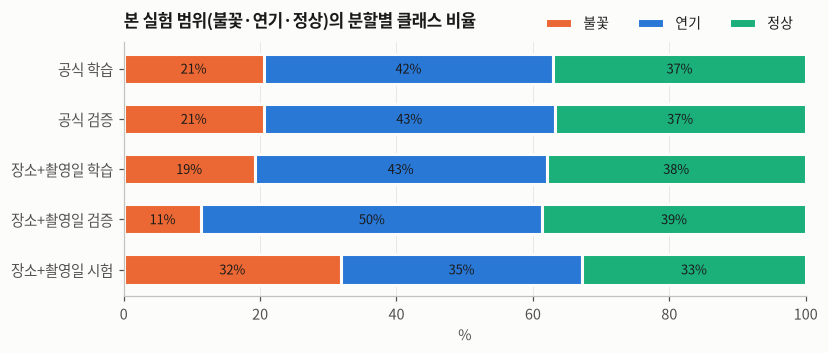

cls,불꽃,연기,정상,합계
공식 학습,77107,159749,139068,375924
공식 검증,9600,19927,17192,46719
장소+촬영일 학습,49406,110213,97701,257320
장소+촬영일 검증,8561,37551,29008,75120
장소+촬영일 시험,28740,31912,29551,90203


In [8]:
cls_split = pd.crosstab(use.split.map(SPLIT_KO), use.cls).reindex(['학습', '검증', '시험'])[CLS + ['제외: 음성 속 연기']]
display(cls_split.assign(합계=cls_split.sum(axis=1)))
both = pd.concat([pd.crosstab('공식 ' + main.official.map(SPLIT_KO), main.cls),
                  pd.crosstab('장소+촬영일 ' + main.split.map(SPLIT_KO), main.cls)])[CLS]
both = both.reindex(['공식 학습', '공식 검증', '장소+촬영일 학습', '장소+촬영일 검증', '장소+촬영일 시험'])
fig, ax = plt.subplots(figsize=(8, 3))
stacked_100(ax, both, CLS_COLOR)
ax.set_title('본 실험 범위(불꽃·연기·정상)의 분할별 클래스 비율')
ax.legend(ncol=3, loc='lower right', bbox_to_anchor=(1, 1.0))
plt.show()
both.assign(합계=both.sum(axis=1))

### 4절 정리

- 63만 장 중 본 실험에 쓰는 사진은 **422,643장**(불꽃 86,707 · 연기 179,676 · 정상 156,260, 약 21 : 43 : 37)이다. 합성 양성 126,107장, 안 쓰는 양성 장소 57,521장, 음성 속 연기 23,729장은 뺐다.
- **폴더 이름(대상)을 클래스로 그대로 쓰면 안 된다.** 연기 폴더 사진 27,448장(백색회색 23,188 + 흑색 4,260)에 화염 박스가 있어 불꽃으로 바뀐다.
- 음성 속 연기는 대부분 굴뚝연기 폴더에서 나온다(21,702장, 그 폴더의 30%).
- 공식 분할은 학습·검증의 클래스 비율이 거의 같지만, 장소+촬영일 분할은 묶음 단위로 나눠 검증 불꽃 11% · 시험 불꽃 32%로 다르다. 그래서 결과는 전체 정확도 하나가 아니라 클래스별 재현율·오경보율로 본다.

## 5. 실제 사진 보기 (표본)

같은 영상의 이웃 프레임은 거의 같으므로 **영상 하나에서 1장씩** 무작위로 뽑는다. 박스 색: 주황 = 화염, 파랑 = 연기, 흰색 = 구름·안개/연무·굴뚝연기.
사진 아래 글자는 `장소 월/일 시간대·날씨`다. 더 많이 보려면 AI Hub 보기 페이지(`aihub_view_server.py`, 포트 8797)를 쓴다.

In [9]:
ann_i = ann.set_index('idx').sort_index()

def per_video(df, n, seed=0):
    return df.sample(frac=1, random_state=seed).drop_duplicates('vid').head(n)

def cap(r):
    d = f'{int(r.date[4:6])}/{int(r.date[6:])}' if isinstance(r.date, str) else '?'
    return f'{r.place[:9]} {d} {r.timezone}·{r.weather}'

def aihub_tiles(rows, cats=None, caption=cap):
    tiles = []
    for r in rows.itertuples():
        a = ann_i.loc[[r.idx]]
        boxes = [(q.x, q.y, q.bw, q.bh, E.CAT[q.cat]) for q in a.itertuples() if cats is None or E.CAT[q.cat] in cats]
        tiles.append(dict(img=E.load_image(r.jpg, r.official), caption=caption(r), boxes=boxes))
    return tiles

for c in CLS:
    rows = per_video(main[main.cls == c], 32, seed=1)
    show_jpeg(E.grid(aihub_tiles(rows), cols=8, tw=240, title=f'{c} · 영상 {len(rows)}개에서 1장씩'))

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 5.1 불꽃 확대: 화염 박스 주변만 잘라 보기

In [10]:
rows = per_video(main[main.cls == '불꽃'], 24, seed=2)
big = ann[(ann.cat == 3) & ann.idx.isin(rows.idx)].sort_values('area').drop_duplicates('idx', keep='last').set_index('idx')
tiles = []
for r in rows.itertuples():
    q = big.loc[r.idx]
    crop, bb = E.crop_box(E.load_image(r.jpg, r.official), (q.x, q.y, q.bw, q.bh), scale=4, min_side=96)
    tiles.append(dict(img=crop, caption=f'{r.place[:8]} 짧은 변 {min(q.bw, q.bh):.0f}px', boxes=[(*bb, '화염')]))
show_jpeg(E.grid(tiles, cols=8, tw=180, th=180, title='화염 박스 주변 (박스의 4배 넓이로 자름, 최소 96px)'))

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 5.2 정상 사진: 방해 요소 종류별 (폴더 이름 기준)

In [11]:
tiles = []
for obj in ['구름', '안개연무', '굴뚝연기']:
    rows = per_video(main[(main.cls == '정상') & (main.folder_obj == obj)], 8, seed=3)
    tiles += aihub_tiles(rows)
show_jpeg(E.grid(tiles, cols=8, tw=240, title='정상: 1줄 구름 · 2줄 안개/연무 · 3줄 굴뚝연기 폴더 (흰 상자 = 방해 요소 박스)'))

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 5.3 뺀 사진과 밤 사진

In [12]:
tiles = aihub_tiles(per_video(img[img.cls == '제외: 음성 속 연기'], 8, seed=4))
tiles += aihub_tiles(per_video(img[img.cls == '제외: 합성 양성'], 8, seed=4))
show_jpeg(E.grid(tiles, cols=8, tw=240, title='제외: 1줄 음성 폴더인데 연기 박스가 있는 사진 · 2줄 합성 양성'))
tiles = aihub_tiles(per_video(main[(main.cls == '불꽃') & (main.timezone == '야간')], 8, seed=5))
tiles += aihub_tiles(per_video(main[(main.cls == '정상') & (main.timezone == '야간')], 8, seed=5))
show_jpeg(E.grid(tiles, cols=8, tw=240, title="시간대 라벨 '야간': 1줄 불꽃 · 2줄 정상"))

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 5절 정리

- **불꽃**: 대부분 공터·길·수목원에 놓인 쇠 화로(불판) 위의 작은 모닥불이다. 밤 사진이 많고, 화면에서 불이 차지하는 부분이 아주 작다(5.1 확대 그림에서 박스 짧은 변 13~79px). 실제 산불(숲이 타는 장면)과 생김새가 달라 결과는 '모의발화 탐지'로 한정해 해석하고, 화로 모양을 지름길로 배울 수 있다는 점도 적어 둔다.
- **연기**: 낮에 연막탄을 피운 장면이 대부분이고, 연기가 화면 가운데에 크게 잡힌다.
- **정상**: 하늘이 화면 위쪽을 차지하는 넓은 풍경이고, 구름·안개 박스가 하늘이나 산등성이를 덮는다. 단풍·마른 풀이 많다(7.2 계절 참고).
- **음성 속 연기**는 주로 공장 굴뚝·지붕 연기(안산 상록구·포천)에 연기 박스가 붙은 사진이다. **합성 양성**은 CCTV·드론 화면에 불꽃·연기를 붙여 넣은 사진이다.
- 시간대 라벨이 '야간'인 정상 사진은 모두 낮 사진이다(7.3에서 숫자로 확인).

## 6. 해상도·파일 크기 (100%)

크기는 JSON 값이 아니라 사진을 열어 잰 값이다(3절에서 둘이 모두 같음을 확인).

cls,불꽃,연기,정상,합계
row_0,,,,
1920×1080,84718,157662,126679,369059
3840×2160,1989,22014,29291,53294
1280×720,0,0,265,265
960×540,0,0,24,24
4032×1816,0,0,1,1


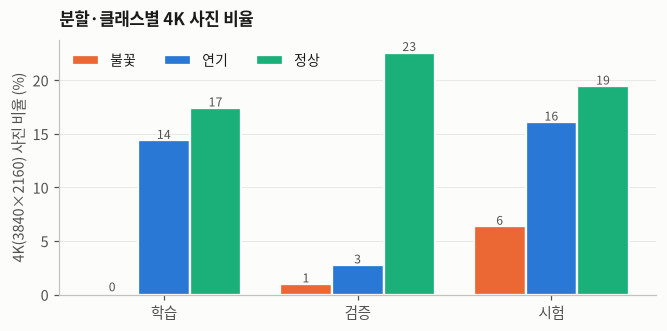

cls,불꽃,연기,정상
split,,,
학습,0.2,14.4,17.4
검증,1.0,2.8,22.6
시험,6.4,16.1,19.4


In [13]:
def res(df):
    return df.w.astype(int).astype(str) + '×' + df.h.astype(int).astype(str)
r_cls = pd.crosstab(res(main), main.cls)[CLS]
r_cls['합계'] = r_cls.sum(axis=1)
display(r_cls.sort_values('합계', ascending=False))
k4 = main.assign(k4=main.w >= 3840).pivot_table(index='split', columns='cls', values='k4', aggfunc='mean').reindex(SPLITS)[CLS] * 100
k4.index = k4.index.map(SPLIT_KO)
fig, ax = plt.subplots(figsize=(7, 3))
grouped_bars(ax, k4, CLS_COLOR, ylabel='4K(3840×2160) 사진 비율 (%)', fmt='{:.0f}')
ax.set_title('분할·클래스별 4K 사진 비율')
ax.legend(ncol=3, loc='upper left')
plt.show()
k4.round(1)

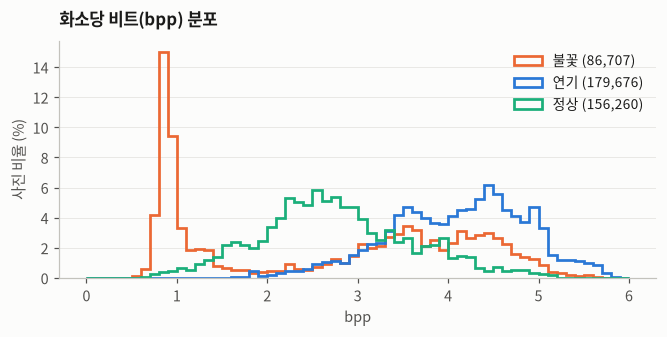

,bpp 중앙값,파일 크기 중앙값 (KB),JPEG 양자화 첫 값 중앙값
cls,,,
불꽃,3.01,785.83,2.0
연기,4.18,1119.04,2.0
정상,2.69,744.06,2.0


In [14]:
# 파일 크기: 화소당 비트(bpp). 압축 정도가 클래스마다 다르면 '파일 크기'가 지름길이 된다
fa = main[['official', 'jpg_name', 'cls', 'w', 'h']].merge(
    full[['src', 'jpg', 'nbytes', 'jpeg_q0']].rename(columns={'src': 'official', 'jpg': 'jpg_name'}), on=['official', 'jpg_name'])
fa['bpp'] = fa.nbytes * 8 / (fa.w * fa.h)
fig, ax = plt.subplots(figsize=(7, 2.8))
step_hist(ax, {c: fa.loc[fa.cls == c, 'bpp'] for c in CLS}, CLS_COLOR, bins=np.linspace(0, 6, 61))
ax.set_title('화소당 비트(bpp) 분포'); ax.set_xlabel('bpp'); ax.set_ylabel('사진 비율 (%)'); ax.legend()
plt.show()
pd.DataFrame({'bpp 중앙값': fa.groupby('cls').bpp.median(), '파일 크기 중앙값 (KB)': fa.groupby('cls').nbytes.median() / 1024,
              'JPEG 양자화 첫 값 중앙값': fa.groupby('cls').jpeg_q0.median()}).reindex(CLS).round(2)

### 6절 정리

- 1920×1080이 87.3%, 3840×2160이 12.6%이고, 나머지(1280×720 265장, 960×540 24장, 4032×1816 1장)는 모두 정상 사진이다.
- **4K 비율이 클래스마다 다르다**: 정상 17~23%, 연기 3~16%, 불꽃 0.2~6.4%(분할마다). 그대로 두면 '4K면 정상'을 배울 수 있다. 3840×2160은 1920×1080으로 줄여 통일하고, 그 밖의 해상도 290장은 뺀다.
- 첫판(split_v1)에서는 분할끼리도 크게 달랐다(시험 정상 60.5% · 학습 정상 7.6%). 4K 사진은 모두 드론 사진이라(전처리 노트북 7.3) 이는 드론 음성이 시험에 몰린 것이었고, split_v2에서 드론 비율을 맞춰 학습 정상 17.4% · 시험 정상 19.4%가 됐다.
- 화소당 비트(bpp)는 연기 4.18 > 불꽃 3.01 > 정상 2.69다. JPEG 압축 설정(양자화 첫 값)은 거의 모두 같으므로(97%가 2) 차이는 사진 내용(질감·밝기)에서 온다. 모델은 파일 크기를 직접 보지 못하지만, 같은 질감 차이가 사진 안에도 있어 지름길이 될 수 있다(11절).

## 7. 촬영 조건·장소·날짜 (100%)
### 7.1 클래스별 조건 분포

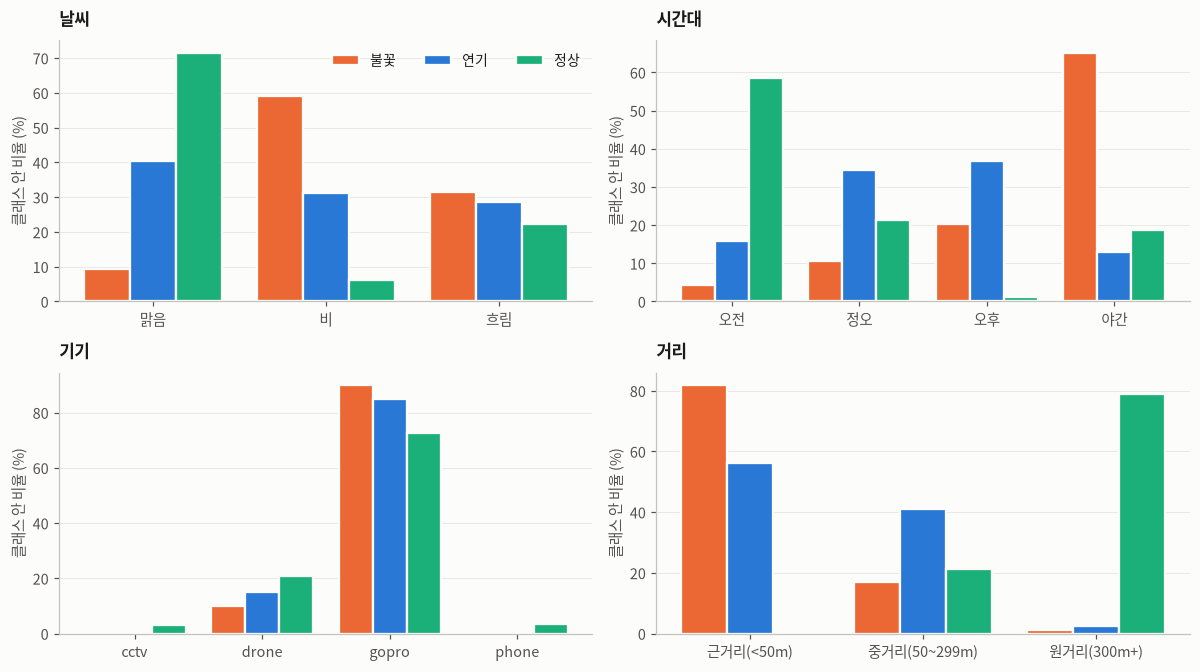

cls                      불꽃    연기    정상
weather  맑음             9.4  40.3  71.5
         비             59.2  31.2   6.3
         흐림            31.4  28.5  22.3
timezone 야간            65.1  13.0  18.8
         오전             4.2  15.7  58.6
         오후            20.2  36.8   1.2
         정오            10.5  34.5  21.4
device   cctv           0.0   0.0   3.2
         drone         10.1  15.1  20.9
         gopro         89.9  84.9  72.6
         phone          0.0   0.0   3.3
dist_bin 근거리(<50m)     81.9  56.2   0.0
         중거리(50~299m)  17.1  41.2  21.1
         원거리(300m+)     1.0   2.6  78.9

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2))
for ax, (col, title) in zip(axes.flat, [('weather', '날씨'), ('timezone', '시간대'), ('device', '기기'), ('dist_bin', '거리')]):
    t = pd.crosstab(main[col], main.cls, normalize='columns')[CLS] * 100
    if col == 'timezone':
        t = t.reindex(['오전', '정오', '오후', '야간'])
    grouped_bars(ax, t, CLS_COLOR, ylabel='클래스 안 비율 (%)')
    ax.set_title(title)
axes[0, 0].legend(ncol=3, loc='upper right')
plt.tight_layout(); plt.show()
pd.concat({col: (pd.crosstab(main[col], main.cls, normalize='columns')[CLS] * 100).round(1)
           for col in ['weather', 'timezone', 'device', 'dist_bin']})

### 7.2 장소와 날짜

In [16]:
pl = main.groupby('cls').agg(장소=('address', 'nunique'), 카메라=('place_cam', 'nunique'), 영상=('vid', 'nunique'),
                             장소_촬영일_묶음=('group', 'nunique'), 사진=('idx', 'size')).reindex(CLS)
top = main.groupby(['cls', 'place']).size().rename('n').reset_index()
pl['가장 많은 장소'] = [f"{g.sort_values('n').iloc[-1].place} {100 * g.n.max() / g.n.sum():.0f}%" for c in CLS for g in [top[top.cls == c]]]
display(pl)
pos_places = pd.crosstab(main[main.cls != '정상'].place, main[main.cls != '정상'].cls)
display(pos_places.assign(합계=pos_places.sum(axis=1)).sort_values('합계', ascending=False))
gn = main[main.cls == '정상']
print(f"정상 장소 {gn.address.nunique()}곳 중 강릉 {gn[gn.address.str.startswith('강원도강릉시')].address.nunique()}곳, "
      f"강릉 정상 사진 비율 {pct(gn.address.str.startswith('강원도강릉시'))}%, 양성과 장소가 겹치는 정상 장소: "
      f"{sorted(set(gn.place) & set(main[main.cls != '정상'].place))}")

,장소,카메라,영상,장소_촬영일_묶음,사진,가장 많은 장소
cls,,,,,,
불꽃,4,88,3024,15,86707,솔향수목원 47%
연기,4,136,7103,16,179676,솔향수목원 57%
정상,54,211,1736,72,156260,대전대덕구대청로 13%


cls,불꽃,연기,합계
place,,,
솔향수목원,40621,102353,142974
죽헌저수지삼거리,11044,38366,49410
시루봉정상입구,25211,17402,42613
춘갑봉공터,9831,21555,31386


정상 장소 54곳 중 강릉 19곳, 강릉 정상 사진 비율 36.1%, 양성과 장소가 겹치는 정상 장소: ['시루봉정상입구']


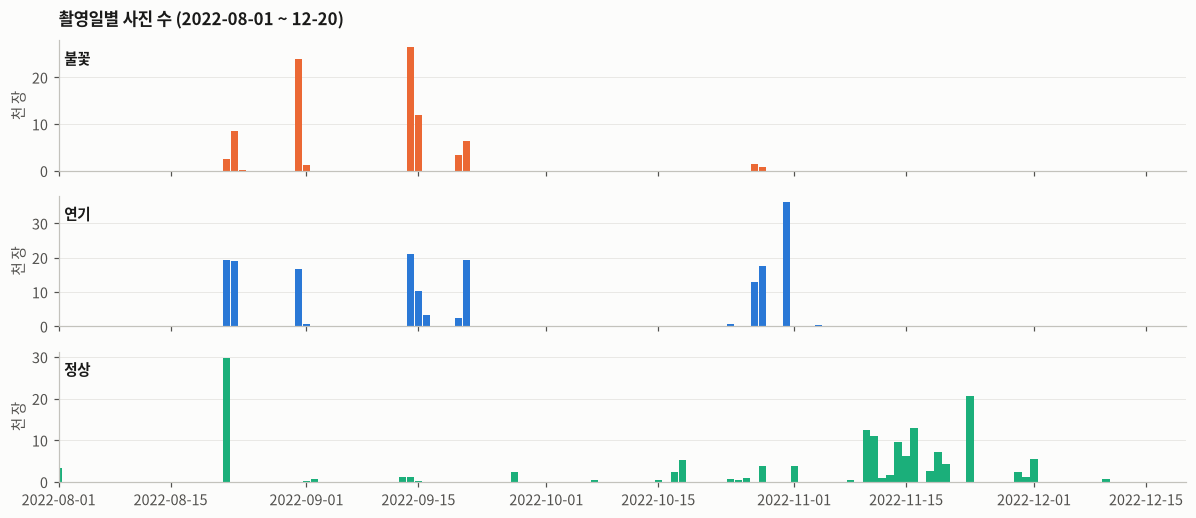

cls,불꽃,연기,정상
촬영 월 (클래스 안 %),,,
2021-07,0.0,0.0,0.0
2021-12,0.0,0.0,0.0
2022-08,40.4,30.7,21.1
2022-09,57.1,31.7,3.9
2022-10,2.6,37.3,9.1
2022-11,0.0,0.3,61.9
2022-12,0.0,0.0,4.0


8~9월 비율: {'불꽃': 97.4, '연기': 62.4, '정상': 25.0} / 10~12월 비율: {'불꽃': 2.6, '연기': 37.6, '정상': 75.0}
그림 밖(2022-08-01 이전) 사진: {'정상': 9} / 장소: ['경남창녕군창녕읍', '제주도애월읍광령리']


촬영 기간: {'불꽃': '20220822 ~ 20221104, 15일', '연기': '20220822 ~ 20221104, 16일', '정상': '20210705 ~ 20221210, 39일'}


In [17]:
day = main.assign(d=pd.to_datetime(main.date, format='%Y%m%d')).groupby(['d', 'cls']).size().unstack(fill_value=0).reindex(columns=CLS)
fig, axes = plt.subplots(3, 1, figsize=(11, 4.8), sharex=True)
for ax, c in zip(axes, CLS):
    ax.bar(day.index, day[c] / 1000, width=0.9, color=CLS_COLOR[c])
    ax.set_ylabel('천 장'); ax.grid(axis='y')
    ax.text(0.005, 0.82, c, transform=ax.transAxes, fontweight='bold', color=INK)
axes[0].set_xlim(pd.Timestamp('2022-08-01'), pd.Timestamp('2022-12-20'))
axes[0].set_title('촬영일별 사진 수 (2022-08-01 ~ 12-20)')
plt.tight_layout(); plt.show()
month = pd.crosstab(main.date.str[:6].map(lambda m: f'{m[:4]}-{m[4:]}'), main.cls, normalize='columns')[CLS] * 100
display(month.round(1).rename_axis('촬영 월 (클래스 안 %)'))
summer = {c: pct(main.loc[main.cls == c, 'date'].str[4:6].isin(['08', '09'])) for c in CLS}
autumn = {c: pct(main.loc[main.cls == c, 'date'].str[4:6].isin(['10', '11', '12'])) for c in CLS}
print('8~9월 비율:', summer, '/ 10~12월 비율:', autumn)
print('그림 밖(2022-08-01 이전) 사진:', main[main.date < '20220801'].groupby('cls').size().to_dict(), '/ 장소:',
      sorted(main[main.date < '20220801'].place.unique()))
print('촬영 기간:', {c: f"{main[main.cls == c].date.min()} ~ {main[main.cls == c].date.max()}, {main[main.cls == c].date.nunique()}일" for c in CLS})

In [18]:
# 날씨가 '장소+촬영일' 묶음에 묶여 있는가: 묶음 안의 날씨 값 종류 수
wg = main.groupby(['cls', 'group']).weather.nunique()
print('날씨가 한 가지뿐인 장소+촬영일 묶음 비율:', {c: f'{pct(wg[c] == 1)}% ({len(wg[c])}묶음)' for c in CLS})
tg = main.groupby(['cls', 'vid']).timezone.nunique()
print('시간대 값이 한 가지뿐인 영상 비율:', {c: f'{pct(tg[c] == 1)}%' for c in CLS})

날씨가 한 가지뿐인 장소+촬영일 묶음 비율: {'불꽃': '93.3% (15묶음)', '연기': '93.8% (16묶음)', '정상': '100.0% (72묶음)'}
시간대 값이 한 가지뿐인 영상 비율: {'불꽃': '99.3%', '연기': '99.9%', '정상': '99.5%'}


### 7.3 시간대 라벨과 실제 밝기 (전수 측정값)

`어두운 사진` = 짧은 변 256px로 줄였을 때 평균 밝기가 50 미만(0~255). 라벨의 '야간'이 실제로 어두운지 본다.

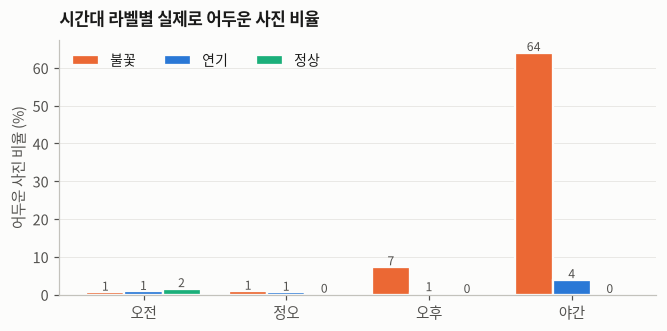

어두운 사진 %             사진 수              
cls            불꽃   연기   정상     불꽃     연기     정상
timezone                                        
오전            0.6  0.8  1.6   3611  28247  91566
정오            0.9  0.6  0.1   9107  61924  33459
오후            7.3  0.5  0.0  17545  66197   1818
야간           64.0  3.9  0.0  56444  23308  29417

어두운 사진 중 불꽃 비율: 91.8 % / 정상 사진 밝기의 하위 1%: 50.7


In [19]:
mf = main.merge(full[['src', 'jpg', 'bright', 'dark_px', 'text']].rename(columns={'src': 'official', 'jpg': 'jpg_name'}),
                on=['official', 'jpg_name'], how='left')
mf['dark'] = mf.bright < 50
TZ = ['오전', '정오', '오후', '야간']
dark = mf.pivot_table(index='timezone', columns='cls', values='dark', aggfunc='mean').reindex(TZ)[CLS] * 100
n_tz = pd.crosstab(mf.timezone, mf.cls).reindex(TZ)[CLS]
fig, ax = plt.subplots(figsize=(7, 3))
grouped_bars(ax, dark, CLS_COLOR, ylabel='어두운 사진 비율 (%)', fmt='{:.0f}')
ax.set_title('시간대 라벨별 실제로 어두운 사진 비율')
ax.legend(ncol=3, loc='upper left')
plt.show()
display(pd.concat({'어두운 사진 %': dark.round(1), '사진 수': n_tz}, axis=1))
print('어두운 사진 중 불꽃 비율:', pct(mf[mf.dark].cls == '불꽃'), '% / 정상 사진 밝기의 하위 1%:',
      round(float(mf[mf.cls == '정상'].bright.quantile(0.01)), 1))

### 7절 정리

- **조건이 클래스와 강하게 묶여 있다.** 불꽃은 비 59% · 야간 65% · 근거리 82%, 정상은 맑음 72% · 오전 59% · 원거리 79%다.
- **장소**: 불꽃·연기는 강릉 4곳(솔향수목원이 각각 47%·57%)이고, 정상은 54곳(강릉 19곳, 사진의 36.1%)이다. 양성과 정상이 겹치는 장소는 시루봉정상입구 1곳뿐이라 모델이 '장소'를 배울 수 있다. 강릉 정상만의 오경보율을 따로 본다.
- **계절**: 불꽃 97%, 연기 62%가 8~9월이고 정상 75%가 10~12월이다. 정상 사진에 단풍·마른 풀이 많은 이유이며, 색으로 클래스를 가르는 지름길이 된다(10.2 색상 분포).
- **날씨**는 장소+촬영일 묶음마다 거의 한 가지다(정상 100%, 불꽃 93%). 날씨별 결과는 '그 장소 그 날'의 결과이고, 날씨만의 영향은 같은 사진에 합성 손상을 입혀 비교해야 한다.
- **시간대 라벨**: '야간' 정상 29,417장 중 실제로 어두운 사진은 0장이다(가장 어두운 것도 밝기 58.7, 정상 전체의 하위 1%도 50.7). 불꽃 '야간'은 64%가 어둡고, 어두운 사진의 91.8%가 불꽃이다. 밤 정상이 없어 **'어두우면 불꽃' 지름길**이 생긴다. 시간대 라벨 대신 실제 밝기를 쓴다.

## 8. 물체(박스) 크기·위치·개수 (박스 100%)

사진마다 **가장 큰** 화염·연기 박스의 짧은 변을 본다(모델이 최소한 이 크기는 봐야 한다). 세 가지 입력 크기에서 잰다:
원본, 학습 입력(가로 1920으로 맞춘 크기 — 4K는 절반), 짧은 변 224로 줄였을 때(ImageNet 기본 입력).

사진 수   10%    중앙값    90%  8px 미만 %
연기 원본              208823.0  81.4  294.8  567.1       0.0
   학습 입력(가로 1920)  208823.0  68.9  279.2  551.6       0.0
   224             208823.0  14.3   57.9  114.4       4.3
화염 원본               86707.0  15.9   36.6   75.6       0.8
   학습 입력(가로 1920)   86707.0  15.8   35.7   75.4       1.0
   224              86707.0   3.3    7.4   15.6      54.7

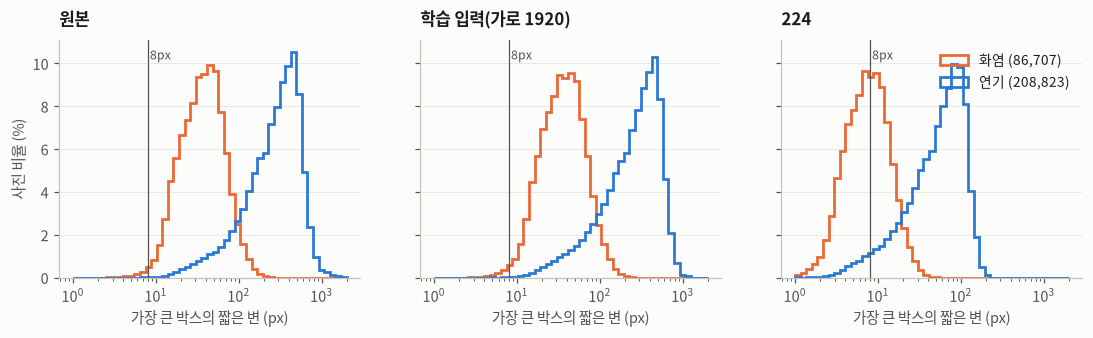

In [20]:
B = ann.merge(main[['idx', 'cls', 'w', 'h', 'split', 'dist_m']], on='idx')
B['name'] = B.cat.map(E.CAT).replace({'흑색연기': '연기', '백색/회색연기': '연기'})
B['short'] = B[['bw', 'bh']].min(axis=1)
Bl = B[B.name.isin(['화염', '연기'])].groupby(['idx', 'name']).agg(
    short=('short', 'max'), w=('w', 'first'), h=('h', 'first'), dist_m=('dist_m', 'first'), cls=('cls', 'first')).reset_index()
Bl['원본'] = Bl.short
Bl['학습 입력(가로 1920)'] = Bl.short * 1920 / Bl.w
Bl['224'] = Bl.short * 224 / Bl[['w', 'h']].min(axis=1)
SIZES = ['원본', '학습 입력(가로 1920)', '224']
qt = {}
for nm, g in Bl.groupby('name'):
    for c in SIZES:
        s = g[c]
        qt[(nm, c)] = {'사진 수': len(s), '10%': s.quantile(.1), '중앙값': s.median(), '90%': s.quantile(.9), '8px 미만 %': pct(s < 8)}
display(pd.DataFrame(qt).T.round(1))

NAME_COLOR = {'화염': CLS_COLOR['불꽃'], '연기': CLS_COLOR['연기']}
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, col in zip(axes, SIZES):
    step_hist(ax, {n: Bl.loc[Bl.name == n, col] for n in ['화염', '연기']}, NAME_COLOR, bins=np.logspace(0, 3.3, 50))
    ax.set_xscale('log'); ax.axvline(8, color=INK2, linewidth=0.8); ax.text(8.5, ax.get_ylim()[1] * 0.92, '8px', fontsize=8, color=INK2)
    ax.set_title(col); ax.set_xlabel('가장 큰 박스의 짧은 변 (px)')
axes[0].set_ylabel('사진 비율 (%)'); axes[2].legend(loc='upper right')
plt.show()

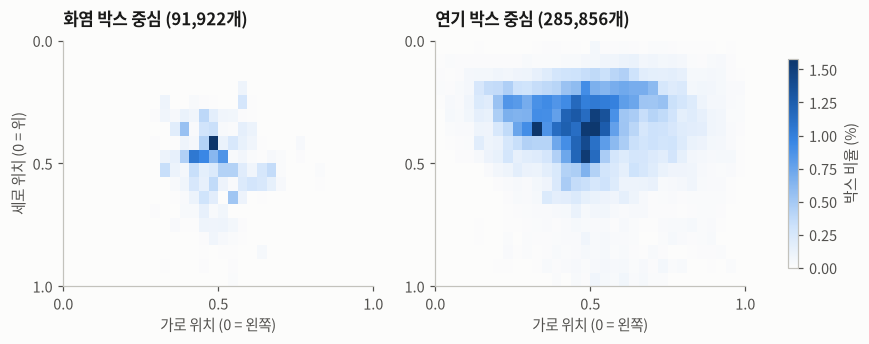

화염 박스 중심이 화면 아래 절반: 41.0%
연기 박스 중심이 화면 아래 절반: 13.3%


In [21]:
# 박스 중심 위치: 화면 어디에 불·연기가 있는가
fig, axes = plt.subplots(1, 2, figsize=(10, 2.9))
for ax, nm in zip(axes, ['화염', '연기']):
    g = B[B.name == nm]
    Hm, _, _ = np.histogram2d(((g.y + g.bh / 2) / g.h).clip(0, .999), ((g.x + g.bw / 2) / g.w).clip(0, .999),
                              bins=[18, 32], range=[[0, 1], [0, 1]])
    im = ax.imshow(Hm / Hm.sum() * 100, cmap=BLUES, extent=[0, 1, 1, 0], aspect='auto')
    ax.set_title(f'{nm} 박스 중심 ({len(g):,}개)'); ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1]); ax.set_xlabel('가로 위치 (0 = 왼쪽)')
axes[0].set_ylabel('세로 위치 (0 = 위)')
fig.colorbar(im, ax=axes, shrink=0.85, label='박스 비율 (%)')
plt.show()
for nm in ['화염', '연기']:
    g = B[B.name == nm]
    print(f'{nm} 박스 중심이 화면 아래 절반: {pct((g.y + g.bh / 2) / g.h > .5)}%')

In [22]:
# 사진당 박스 수와 거리 라벨별 화염 크기
nb = main.assign(n_obj=main[CATS].sum(axis=1)).groupby('cls').n_obj.describe()[['mean', '50%', 'max']].reindex(CLS).round(2)
display(nb.rename(columns={'mean': '사진당 박스 평균', '50%': '중앙값', 'max': '최대'}))
fl = Bl[Bl.name == '화염'].copy()
fl['거리'] = pd.cut(fl.dist_m, [0, 19, 49, 99, 199, 1e9], labels=['<20m', '20~49m', '50~99m', '100~199m', '200m+'])
fl.groupby('거리', observed=True)['원본'].agg(사진='size', 중앙값='median', 상위10=lambda s: s.quantile(.9)).round(1)

,사진당 박스 평균,중앙값,최대
cls,,,
불꽃,1.49,1.0,8.0
연기,1.52,1.0,16.0
정상,1.71,1.0,10.0


,사진,중앙값,상위10
거리,,,
<20m,61981,40.4,82.9
20~49m,9002,26.2,55.3
50~99m,2733,22.0,40.5
100~199m,10369,31.7,53.7
200m+,2622,42.0,62.2


### 8절 정리

- **화염은 아주 작다.** 가장 큰 화염 박스의 짧은 변 중앙값이 원본 36.6px, 학습 입력(가로 1920) 35.7px이고, 224로 줄이면 7.4px로 54.7%가 8px 미만이 된다. 그래서 입력을 줄이지 않는다(1920×972).
- 연기는 원본 중앙값 295px로 충분히 크다(224로 줄여도 58px).
- **위치**: 화염 박스 중심은 화면 가운데 근처(아래 절반 41%), 연기는 가운데보다 위(아래 절반 13%)에 있다. 가운데 자르기를 하면 일부가 잘리므로, 자르는 것은 위 10% 글자 띠만으로 한다.
- **거리 라벨과 화염 크기가 비례하지 않는다**(200m 이상 중앙값 42px > 50~99m 22px). 거리 라벨만으로 크기를 대신할 수 없으니, 결과는 박스 크기 구간별로도 본다.

## 9. 방해 요소: 구름 · 안개/연무 · 굴뚝연기 (정상 사진 100%)

가설의 핵심 변수다. 음성 사진에는 방해 요소 박스(다각형)가 있어, 종류와 **화면에서 차지하는 면적**을 잴 수 있다.
면적 비율 = 같은 종류 다각형 넓이의 합 ÷ 사진 넓이(겹치면 1로 자름).

In [23]:
DIST = ['구름', '안개/연무', '굴뚝연기']
N = main[main.cls == '정상'].copy()
ar = (ann[ann.cat.isin([4, 5, 6]) & ann.idx.isin(N.idx)].drop_duplicates(['idx', 'cat', 'x', 'y', 'bw', 'bh'])
      .groupby(['idx', 'cat']).poly_area.sum().unstack(fill_value=0))
ar.columns = ['a_' + E.CAT[c] for c in ar.columns]
N = N.merge(ar, left_on='idx', right_index=True, how='left').fillna({f'a_{d}': 0 for d in DIST})
for d in DIST:
    N[f'f_{d}'] = (N[f'a_{d}'] / (N.w * N.h)).clip(0, 1)
N['f_구름안개'] = (N['f_구름'] + N['f_안개/연무']).clip(0, 1)
N['combo'] = N[DIST].gt(0).apply(lambda r: ' + '.join(d for d in DIST if r[d]) or '(없음)', axis=1)
combo = N.combo.value_counts().rename('사진').to_frame()
combo['%'] = (100 * combo.사진 / len(N)).round(1)
display(combo)
pd.crosstab(N.folder_obj, N.combo).rename_axis(index='폴더 대상', columns='실제로 붙은 박스')

,사진,%
combo,,
구름,65067,41.6
굴뚝연기,37079,23.7
안개/연무,19823,12.7
구름 + 안개/연무,17977,11.5
구름 + 굴뚝연기,8558,5.5
안개/연무 + 굴뚝연기,7668,4.9
구름 + 안개/연무 + 굴뚝연기,88,0.1


실제로 붙은 박스,구름,구름 + 굴뚝연기,구름 + 안개/연무,구름 + 안개/연무 + 굴뚝연기,굴뚝연기,안개/연무,안개/연무 + 굴뚝연기
폴더 대상,,,,,,,
구름,65067,3072,1810,8,0,0,0
굴뚝연기,0,5486,0,80,37079,0,7668
안개연무,0,0,16167,0,0,19823,0


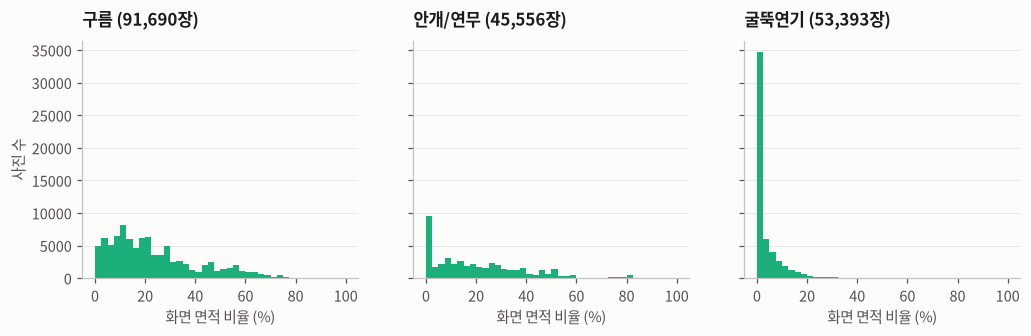

구름+안개/연무 면적 구간별 정상 사진 수


split,학습,검증,시험,합계
구간,,,,
<5%,31165,4386,9643,45194
5~20%,31322,9197,5740,46259
≥20%,35214,15425,14168,64807


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for ax, d in zip(axes, DIST):
    s = N.loc[N[d] > 0, f'f_{d}'] * 100
    ax.hist(s, bins=np.linspace(0, 100, 41), color=CLS_COLOR['정상'])
    ax.set_title(f'{d} ({len(s):,}장)'); ax.set_xlabel('화면 면적 비율 (%)'); ax.grid(axis='y')
axes[0].set_ylabel('사진 수')
plt.show()
N['구간'] = pd.cut(N['f_구름안개'] * 100, [-1, 5, 20, 101], labels=['<5%', '5~20%', '≥20%'])
bins_split = pd.crosstab(N.구간, N.split.map(SPLIT_KO))[['학습', '검증', '시험']]
print('구름+안개/연무 면적 구간별 정상 사진 수')
bins_split.assign(합계=bins_split.sum(axis=1))

In [25]:
# 종류별 장소 수 (분할별) — 장소가 적으면 그 종류의 결과는 몇 곳의 결과다
places = N.groupby(['folder_obj', 'split']).address.nunique().unstack()[SPLITS].rename(columns=SPLIT_KO)
places['전체 장소'] = N.groupby('folder_obj').address.nunique()
places['사진'] = N.groupby('folder_obj').size()
display(places.rename_axis('폴더 대상'))
# 구름이 화면 아래쪽까지 내려와 있는가 (산 능선 근처 구름은 연기처럼 보일 수 있다)
cb = ann[(ann.cat == 4) & ann.idx.isin(N.idx)].merge(N[['idx', 'h']], on='idx')
low = cb.assign(bottom=(cb.y + cb.bh) / cb.h).groupby('idx').bottom.max() > 0.5
print(f'구름 박스가 있는 정상 사진 {len(low):,}장 중 구름이 화면 아래 절반까지 내려온 사진 {pct(low)}%')

split,학습,검증,시험,전체 장소,사진
폴더 대상,,,,,
구름,24,10,19,47,69957
굴뚝연기,10,3,3,15,50313
안개연무,2,2,7,9,35990


구름 박스가 있는 정상 사진 91,690장 중 구름이 화면 아래 절반까지 내려온 사진 29.0%


In [26]:
# 양성 사진 속 방해 요소: 구름·안개가 낀 산불 사진이 실제로 얼마나 있나
P = main[main.cls != '정상']
pos_d = pd.DataFrame({d: P.groupby(['split', 'cls'])[d].apply(lambda s: int((s > 0).sum())) for d in DIST})
pos_d['양성 사진'] = P.groupby(['split', 'cls']).size()
pos_d.rename(index=SPLIT_KO, level=0).reindex(['학습', '검증', '시험'], level=0)

구름  안개/연무  굴뚝연기   양성 사진
split cls                            
학습    불꽃    1919      0     0   49406
      연기   13116      9   250  110213
검증    불꽃       0      8     0    8561
      연기    1421    633     2   37551
시험    불꽃       0      0     0   28740
      연기      95      0     0   31912

### 9절 정리

- **정상 156,260장 모두에 방해 요소 박스가 1개 이상 있다**(방해 요소가 없는 정상 0장). 구름만 41.6%, 굴뚝연기만 23.7%, 안개/연무만 12.7%, 두 가지 이상 22.0%다.
- **폴더 이름과 실제 박스가 다르다.** 안개연무 폴더 사진의 45%(16,167장)에 구름 박스도 있다. 방해 요소 종류는 폴더가 아니라 박스로 정한다.
- **면적**: 구름은 0~70%에 고르게 퍼져 있고, 굴뚝연기는 76%가 5% 미만으로 작다. 구름+안개 면적 구간별 시험 정상 사진은 <5% 9,643장, 5~20% 5,740장, ≥20% 14,168장으로, 구간별 오경보율을 비교할 만큼 있다(원본 화면 기준 — 위 10%를 자른 화면으로 다시 잰 값은 전처리 노트북 4.2).
- **장소가 적다**: 안개/연무 폴더 정상은 전체 9곳(학습 2 · 검증 2 · 시험 7 — 같은 장소가 날짜별로 여러 분할에 들 수 있다), 굴뚝연기는 15곳이다. 안개 결과는 몇 곳의 결과이므로 장소별로 같이 보여 준다.
- 구름이 화면 아래 절반까지 내려온 사진이 29.0%다. 산등성이에 걸친 구름(연기와 헷갈리기 쉬운 경우)이 충분히 있다.
- **양성 쪽**: 시험 양성 중 구름 박스가 있는 사진은 연기 95장뿐(불꽃 0장)이고 안개 박스는 0장이다. '구름·안개 속 산불을 놓치는가'는 실제 사진으로 잴 수 없고 합성 안개로만 본다.

## 10. 픽셀 통계 (10% 표본)

모든 값은 짧은 변을 256px로 줄여서 잰다. 밝기 = 회색조 평균(0~255), 대비 = 회색조 표준편차, 채도 = HSV 채도 평균, 선명도 = 라플라시안 분산,
어두운 화소 = 회색조 30 미만 비율, 회색 화소 = 채도 40 미만 비율, 불꽃색 화소 = 색상 0~60°·340~360°이면서 채도 >100, 명도 >150인 비율.

### 10.1 표본 뽑기와 대표성 확인

본 실험 범위의 영상마다 프레임을 순서대로 놓고 10장 중 1장을 고른다(시작 위치는 영상마다 무작위, 영상이 10장보다 짧으면 1장).
기본 5개 값은 63만 장 전수 측정 결과가 있으므로, 표본의 중앙값이 전수와 얼마나 다른지 확인한다.

In [27]:
S = use.sort_values(['vid', 'frame']).copy()
rank = S.groupby('vid').cumcount()
size = S.groupby('vid').vid.transform('size')
u = pd.Series(np.random.default_rng(0).random(S.vid.nunique()), index=S.vid.unique())
S = S[(rank % 10) == np.floor(S.vid.map(u) * np.minimum(10, size)).astype(int)]
px = E.aihub_pixels(S[['official', 'jpg']].rename(columns={'official': 'src'}), REBUILD)
S = S.merge(px.rename(columns={'src': 'official', 'w': 'pw', 'h': 'ph'}), on=['official', 'jpg'], how='left')
S['bpp'] = S.nbytes * 8 / (S.pw * S.ph)
S['short'] = S[['pw', 'ph']].min(axis=1)
print(f'표본 {len(S):,}장 = 본 실험 범위의 {100 * len(S) / len(use):.1f}%, 열기 실패 {int(S["error"].notna().sum()) if "error" in S else 0}장')
display(pd.crosstab(S.cls, S.split.map(SPLIT_KO))[['학습', '검증', '시험']])

F5 = ['bright', 'contrast', 'sat', 'sharp', 'dark_px']
uf = use.merge(full[['src', 'jpg'] + F5].rename(columns={'src': 'official', 'jpg': 'jpg_name'}), on=['official', 'jpg_name'])
rep = pd.concat({'전수': uf.groupby('cls')[F5].median(), '10% 표본': S.groupby('cls')[F5].median()}, axis=1)
display(rep.round(3))
print('표본 중앙값 ÷ 전수 중앙값 - 1 (%):')
pd.DataFrame({f: (rep[('10% 표본', f)] / rep[('전수', f)] - 1) * 100 for f in F5 if f != 'dark_px'}).round(2)

표본 45,864장 = 본 실험 범위의 10.3%, 열기 실패 0장


split,학습,검증,시험
cls,,,
불꽃,5151,916,2927
연기,11517,3892,3323
정상,9835,2915,3014
제외: 음성 속 연기,1629,133,612


전수                                      10% 표본                                   
              bright contrast     sat     sharp dark_px   bright contrast     sat     sharp dark_px
cls                                                                                                
불꽃            77.661   42.777  73.998  1230.361   0.200   80.977   43.824  73.006  1285.312   0.190
연기           101.949   55.534  67.689  2869.951   0.072  101.918   55.585  67.664  2874.904   0.072
정상           111.478   60.527  66.841  1081.283   0.052  111.504   60.529  66.754  1082.015   0.052
제외: 음성 속 연기  101.431   56.670  74.018  2361.955   0.054  101.449   56.577  74.025  2358.430   0.054

표본 중앙값 ÷ 전수 중앙값 - 1 (%):


,bright,contrast,sat,sharp
cls,,,,
불꽃,4.27,2.45,-1.34,4.47
연기,-0.03,0.09,-0.04,0.17
정상,0.02,0.00,-0.13,0.07
제외: 음성 속 연기,0.02,-0.16,0.01,-0.15


### 10.2 클래스별 분포

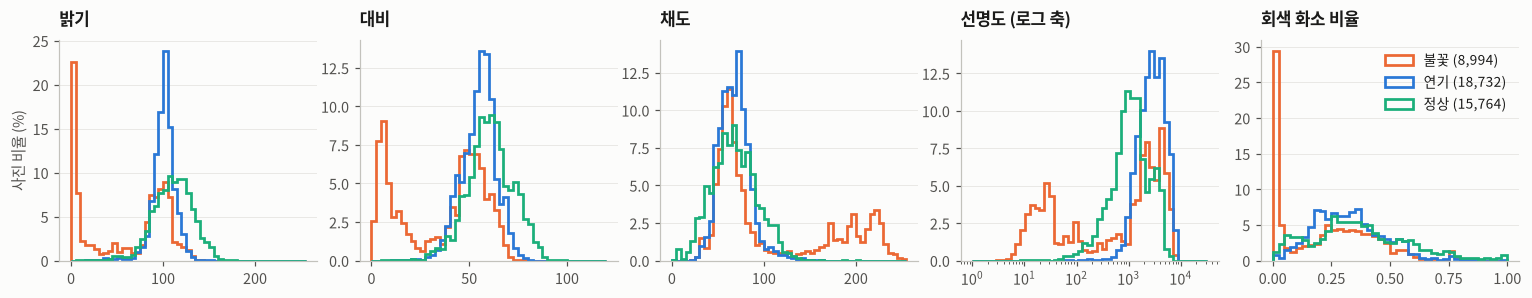

,bright,contrast,sat,sharp,gray_px,dark_px,fire_px
cls,,,,,,,
불꽃,80.977,43.824,73.006,1285.312,0.229,0.190,0.001
연기,101.918,55.585,67.664,2874.904,0.311,0.072,0.002
정상,111.504,60.529,66.754,1082.015,0.347,0.052,0.001


불꽃색 화소가 일정 비율 이상인 사진 (%)


,불꽃색 화소 ≥ 0.1%,불꽃색 화소 ≥ 1%,불꽃색 화소 ≥ 5%
cls,,,
불꽃,41.9,8.2,1.3
연기,56.7,21.5,9.9
정상,47.3,28.8,12.9


In [28]:
sm = S[S.cls.isin(CLS)].copy()
FEATS = [('bright', '밝기', np.linspace(0, 255, 52), False), ('contrast', '대비', np.linspace(0, 120, 49), False),
         ('sat', '채도', np.linspace(0, 255, 52), False), ('sharp', '선명도 (로그 축)', np.logspace(0, 4.5, 50), True),
         ('gray_px', '회색 화소 비율', np.linspace(0, 1, 41), False)]
fig, axes = plt.subplots(1, len(FEATS), figsize=(14, 2.8), sharey=False)
for ax, (f, title, bins, logx) in zip(axes, FEATS):
    step_hist(ax, {c: sm.loc[sm.cls == c, f] for c in CLS}, CLS_COLOR, bins=bins)
    if logx: ax.set_xscale('log')
    ax.set_title(title)
axes[0].set_ylabel('사진 비율 (%)'); axes[-1].legend(loc='upper right')
plt.tight_layout(); plt.show()
display(sm.groupby('cls')[[f for f, *_ in FEATS] + ['dark_px', 'fire_px']].median().reindex(CLS).round(3))
fire_tab = pd.DataFrame({f'불꽃색 화소 ≥ {t * 100:g}%': sm.groupby('cls').fire_px.apply(lambda s: pct(s >= t)) for t in (0.001, 0.01, 0.05)}).reindex(CLS)
print('불꽃색 화소가 일정 비율 이상인 사진 (%)'); fire_tab

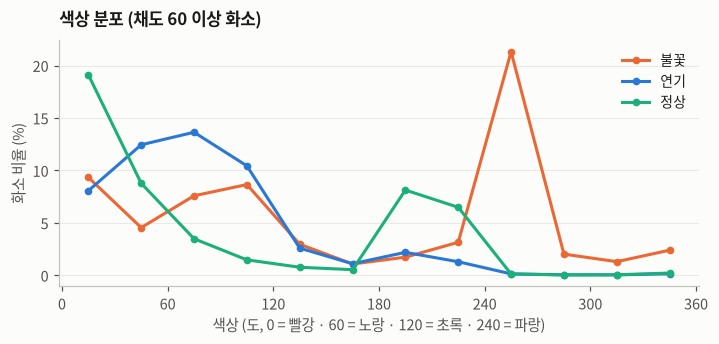

In [29]:
# 색상 분포: 채도 60 이상 화소의 색상(30도 간격)별 비율의 평균
HUE = [f'hue{i:02d}' for i in range(E.HUE_BINS)]
fig, ax = plt.subplots(figsize=(7.5, 2.9))
for c in CLS:
    ax.plot(np.arange(15, 360, 30), sm.loc[sm.cls == c, HUE].mean() * 100, color=CLS_COLOR[c], marker='o', markersize=4, label=c)
ax.set_xticks(range(0, 361, 60)); ax.set_xlabel('색상 (도, 0 = 빨강 · 60 = 노랑 · 120 = 초록 · 240 = 파랑)')
ax.set_ylabel('화소 비율 (%)'); ax.set_title('색상 분포 (채도 60 이상 화소)'); ax.grid(axis='y'); ax.legend()
plt.show()

### 10.3 방해 요소가 있는 정상 사진과 연기 사진 비교

구름·안개가 낀 정상 사진이 픽셀 값으로 연기 사진과 얼마나 비슷한지 본다. 점 = 중앙값, 선 = 25~75% 범위.

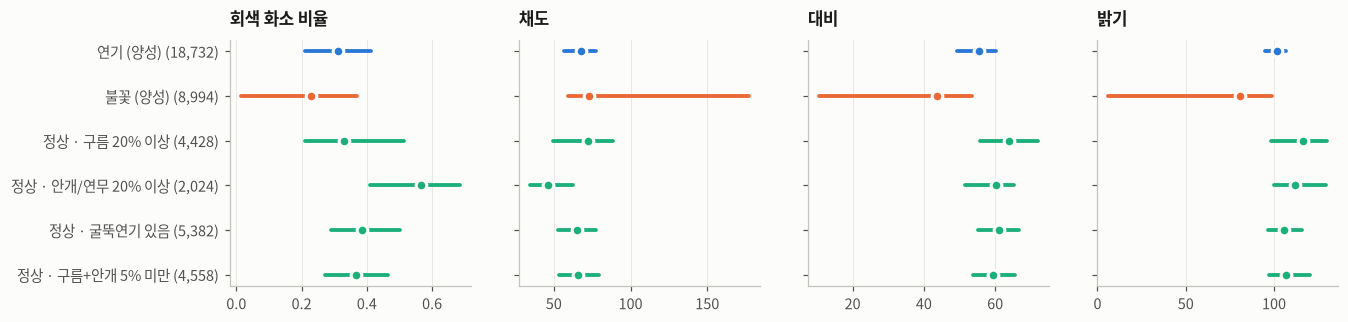

,gray_px,sat,contrast,bright
연기 (양성),0.311,67.664,55.585,101.918
불꽃 (양성),0.229,73.006,43.824,80.977
정상 · 구름 20% 이상,0.330,72.138,63.954,116.406
정상 · 안개/연무 20% 이상,0.565,46.135,60.239,111.645
정상 · 굴뚝연기 있음,0.385,64.970,60.988,105.857
정상 · 구름+안개 5% 미만,0.368,65.979,59.294,106.637


In [30]:
sn = S[S.cls == '정상'].merge(N[['idx', 'f_구름', 'f_안개/연무', 'f_굴뚝연기', 'f_구름안개']], on='idx')
groups = {'연기 (양성)': S[S.cls == '연기'], '불꽃 (양성)': S[S.cls == '불꽃'],
          '정상 · 구름 20% 이상': sn[sn['f_구름'] >= .2], '정상 · 안개/연무 20% 이상': sn[sn['f_안개/연무'] >= .2],
          '정상 · 굴뚝연기 있음': sn[sn['f_굴뚝연기'] > 0], '정상 · 구름+안개 5% 미만': sn[sn['f_구름안개'] < .05]}
gcol = {k: CLS_COLOR['연기'] if k.startswith('연기') else CLS_COLOR['불꽃'] if k.startswith('불꽃') else CLS_COLOR['정상'] for k in groups}
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for ax, (f, title) in zip(axes, [('gray_px', '회색 화소 비율'), ('sat', '채도'), ('contrast', '대비'), ('bright', '밝기')]):
    for yi, (k, g) in enumerate(groups.items()):
        q1, q2, q3 = g[f].quantile([.25, .5, .75])
        ax.plot([q1, q3], [yi, yi], color=gcol[k], linewidth=2.5, solid_capstyle='round')
        ax.plot(q2, yi, 'o', color=gcol[k], markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.set_title(title); ax.grid(axis='x')
axes[0].set_yticks(range(len(groups)), [f'{k} ({len(g):,})' for k, g in groups.items()]); axes[0].invert_yaxis()
plt.show()
pd.DataFrame({k: g[['gray_px', 'sat', 'contrast', 'bright']].median() for k, g in groups.items()}).T.round(3)

In [31]:
# 화면 글자: 드론 사진 왼쪽 위의 날짜·GPS 글자 점수(analyze_aihub_images.py — 글자가 있으면 140 이상, 없으면 0 근처)
txt = mf.assign(has_text=mf.text > 100).groupby('cls').has_text.mean().reindex(CLS) * 100
print('왼쪽 위에 날짜·GPS 글자가 있는 사진 비율 (%):', txt.round(1).to_dict())

왼쪽 위에 날짜·GPS 글자가 있는 사진 비율 (%): {'불꽃': 4.2, '연기': 2.2, '정상': 0.7}


### 10절 정리

- **10% 표본(45,864장)으로 충분하다.** 전수와 비교한 중앙값 차이가 연기·정상은 0.2% 이내이고, 불꽃만 최대 4.5%다(밤 프레임이 몇몇 영상에 몰려 있어서).
- 불꽃은 밤 사진이 많아 밝기·대비·선명도가 낮은 쪽에 몰리고, 채도가 높은 쪽(150~250)에 두 번째 봉우리가 있다(밤 화소의 색 잡음).
- **색상**: 불꽃 사진은 240~270°(파랑) 화소가 많다. 밤 사진의 어두운 화소가 파랗게 찍힌 것이다. 정상은 0~30°(빨강·주황, 단풍), 연기는 30~120°(노랑~초록, 여름 숲)가 많다. 색만으로도 클래스가 꽤 갈린다(계절·밤 지름길).
- **불꽃색 화소는 불꽃 사진보다 정상 사진에 더 많다**(1% 이상인 사진: 불꽃 8.2%, 정상 28.8%). 불꽃이 작고, 단풍·마른 풀이 불꽃색이기 때문이다. 색 규칙으로는 불꽃을 찾을 수 없다.
- **방해 요소와 연기(10.3)**: 구름이 20% 넘게 낀 정상은 회색 화소 비율 0.33 · 채도 72로 연기 사진(0.31 · 68)과 거의 같고, 안개/연무가 20% 넘는 정상은 연기보다 더 회색이다(0.57, 채도 46). 픽셀 통계로는 구름·안개 정상과 연기가 잘 갈리지 않는다는 뜻이고, '구름·안개가 연기 오경보를 부른다'는 가설을 시험할 근거가 된다.
- 왼쪽 위 날짜·GPS 글자는 불꽃 4.2%, 연기 2.2%, 정상 0.7%에 있다. 위 10%를 잘라 없앤다.

## 11. 지름길 점검: 사진 내용 없이 숫자 몇 개로 클래스를 맞히는 정도

학습 쪽에서 깊이 2 결정 나무(클래스 균형 가중치)를 만들고 검증·시험 쪽에서 **균형 정확도**(클래스별 재현율의 평균)를 잰다. 찍기 수준은 33.3%다.
값이 높을수록 모델이 연기·불꽃 대신 해상도·압축·밝기 같은 지름길로 점수를 낼 수 있다는 뜻이다.

In [32]:
FS = {'해상도·파일 크기': ['short', 'bpp'],
      '밝기·색·선명도': ['bright', 'contrast', 'sat', 'sharp', 'dark_px', 'fire_px', 'gray_px'],
      '전부': ['short', 'bpp', 'bright', 'contrast', 'sat', 'sharp', 'dark_px', 'fire_px', 'gray_px']}
tr = sm[sm.split == 'train']
rows, trees = [], {}
for te_name in ['val', 'test']:
    te = sm[sm.split == te_name]
    row = {}
    for fs, cols in FS.items():
        acc, desc = E.shortcut_tree(tr, te, cols, label='cls')
        row[fs + ' (%)'] = round(100 * acc, 1)
        trees[(te_name, fs)] = desc
    rows.append(pd.Series(row, name=f'학습 → {SPLIT_KO[te_name]}'))
short_tab = pd.DataFrame(rows)
short_tab['찍기 (%)'] = 33.3
display(short_tab)
print('[전부 · 학습 → 시험] 찾은 규칙'); print(trees[('test', '전부')])

,해상도·파일 크기 (%),밝기·색·선명도 (%),전부 (%),찍기 (%)
학습 → 검증,49.3,52.6,55.9,33.3
학습 → 시험,63.4,68.4,71.4,33.3


[전부 · 학습 → 시험] 찾은 규칙
bright < 67.56
   fire_px < 8.585e-06
      → 정상
   fire_px ≥ 8.585e-06
      → 불꽃
bright ≥ 67.56
   bpp < 3.175
      → 정상
   bpp ≥ 3.175
      → 연기


### 11절 정리

- 사진 내용 없이 숫자 9개만으로 균형 정확도가 **시험 71.4%, 검증 55.9%**다(찍기 33.3%). 해상도·파일 크기 두 개만으로도 시험 63.4%다.
- 찾은 규칙은 '어두우면(밝기 < 67.6) 불꽃색 화소가 조금이라도 있을 때 불꽃, 밝으면 bpp가 낮을 때 정상 · 높을 때 연기'로, 7.3의 밤 지름길과 6절의 질감(bpp) 차이 그대로다.
- 시험이 검증보다 높은 이유는 시험 불꽃의 73%가 '야간' 사진이라 '어두우면 불꽃' 규칙이 잘 맞기 때문이다(검증 불꽃은 6%만 '야간'). 양성 묶음은 분할을 고칠 때 옮기지 않았으므로 이 차이는 그대로다.
- 모델 성능을 보고할 때 이 기준선을 함께 적는다. 전처리(해상도 통일, 글자 띠 자르기) 뒤 다시 잰 값은 전처리 노트북 7.2에 있다(이진 분류, 찍기 50%: 처리 전 9개 78.9% → 처리 후 픽셀 7개 71.8%).

## 12. 중복·누수

사진마다 32×18 회색 썸네일(밝기 평균·대비를 맞춤)의 평균 절대차를 잰다. **차이 < 6이면 거의 같은 사진**이다(`check_aihub_leak.py`와 같은 척도).
- 공식 분할: 공식 검증 사진(클래스당 1,000장)마다 **같은 카메라**의 공식 학습 사진 전부와 비교
- 장소+촬영일 분할(split_v2): 검증·시험 사진(분할·클래스당 1,000장)마다 **같은 장소**의 학습 사진 전부와 비교

In [33]:
key = pd.Series(np.arange(len(full)), index=pd.MultiIndex.from_arrays([full.src, full.jpg]))
main['k'] = key.reindex(pd.MultiIndex.from_arrays([main.official, main.jpg_name])).to_numpy()
print('썸네일 없는 사진:', int(main.k.isna().sum()))

def leak(queries, cands, by):
    cand = {k: g.k.to_numpy(int) for k, g in cands.groupby(by)}
    out = []
    for kv, g in queries.groupby(by):
        if kv in cand:
            d, j = E.nearest_diff(TH, g.k.to_numpy(int), cand[kv])
        else:
            d, j = np.full(len(g), np.inf), np.full(len(g), -1)
        out.append(g.assign(d=d, near=j))
    return pd.concat(out)

t0 = time.time()
q_off = main[main.official == 'val'].groupby('cls').sample(1000, random_state=0)
r_off = leak(q_off, main[main.official == 'train'], 'place_cam').assign(기준='공식 분할', 분할='검증')
q_sp = main[main.split.isin(['val', 'test'])].groupby(['split', 'cls']).sample(1000, random_state=0)
r_sp = leak(q_sp, main[main.split == 'train'], 'address').assign(기준='장소+촬영일 분할', 분할=lambda d: d.split.map(SPLIT_KO))
R = pd.concat([r_off, r_sp])
leak_tab = R.groupby(['기준', '분할', 'cls']).agg(
    사진=('d', 'size'), 같은_카메라·장소가_학습에_있음=('d', lambda s: pct(np.isfinite(s))),
    거의_같음=('d', lambda s: pct(s < 6)),
    차이_중앙값=('d', lambda s: round(float(np.median(s[np.isfinite(s)])), 1) if np.isfinite(s).any() else np.nan))
print(f'{time.time() - t0:.0f}초 (비율은 %)')
leak_tab

썸네일 없는 사진: 0


4초 (비율은 %)


사진  같은_카메라·장소가_학습에_있음  거의_같음  차이_중앙값
기준        분할 cls                                        
공식 분할     검증 불꽃   1000              100.0   99.4     0.7
             연기   1000              100.0   98.7     0.7
             정상   1000              100.0   97.9     0.4
장소+촬영일 분할 검증 불꽃   1000                9.4    0.0    18.8
             연기   1000               48.5    0.0    19.4
             정상   1000               32.5    0.0    11.3
          시험 불꽃   1000                5.2    0.0    25.8
             연기   1000               40.2    0.0    21.8
             정상   1000               16.3    0.0    17.4

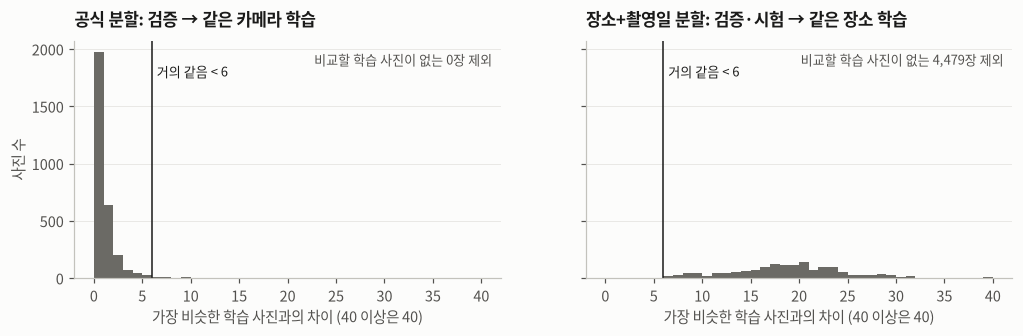

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
for ax, (t, g) in zip(axes, [('공식 분할: 검증 → 같은 카메라 학습', r_off), ('장소+촬영일 분할: 검증·시험 → 같은 장소 학습', r_sp)]):
    v = g.d[np.isfinite(g.d)]
    ax.hist(v.clip(upper=40), bins=np.arange(0, 41, 1), color=NEUTRAL)
    ax.axvline(6, color=INK, linewidth=1); ax.text(6.5, ax.get_ylim()[1] * 0.85, '거의 같음 < 6', fontsize=8.5)
    ax.set_title(t); ax.set_xlabel('가장 비슷한 학습 사진과의 차이 (40 이상은 40)'); ax.grid(axis='y')
    ax.text(0.98, 0.9, f'비교할 학습 사진이 없는 {int((~np.isfinite(g.d)).sum()):,}장 제외', transform=ax.transAxes, ha='right', fontsize=8.5, color=INK2)
axes[0].set_ylabel('사진 수')
plt.show()

In [35]:
# 공식 분할에서 '거의 같음'으로 나온 쌍 보기: 왼쪽 검증, 오른쪽 학습
kk = main.dropna(subset=['k'])
inv = kk.set_index(kk.k.astype(int))
tiles = []
for c in CLS:
    for r in r_off[(r_off.cls == c) & (r_off.d < 6)].sample(2, random_state=0).itertuples():
        t = inv.loc[r.near]
        tiles.append(dict(img=E.load_image(r.jpg, r.official), caption=f'검증 {c} · 프레임 {r.frame}'))
        tiles.append(dict(img=E.load_image(t.jpg, t.official), caption=f'학습 · 프레임 {t.frame} · 차이 {r.d:.1f}'))
show_jpeg(E.grid(tiles, cols=4, tw=300, title='공식 분할: 검증 사진(왼쪽)과 가장 비슷한 학습 사진(오른쪽)'))

[AI Hub 사진 출력은 공개 저장소에서 뺐습니다. AI Hub 이용 약관상 사진은 다시 배포할 수 없습니다. 데이터를 받아 노트북을 다시 실행하면 이 자리에 사진이 나옵니다.]


### 12절 정리

- **공식 분할**: 검증 3,000장 중 98.7%가 같은 카메라의 학습 사진과 거의 같다(차이 중앙값 0.4~0.7). 위 그림처럼 프레임 몇십 개 차이의 같은 장면이다. 공식 분할로 재면 외운 것도 맞힌 것이 된다.
- **장소+촬영일 분할(split_v2)**: 검증·시험 6,000장 중 거의 같은 사진은 0장이다. 같은 장소의 학습 사진이 있어도 차이 중앙값이 11.3~25.8로 다른 장면이다(분할·클래스당 2,000장으로 잰 `check_aihub_split.py`도 12,000장 중 0장).
- 시험 불꽃은 95%가 학습에 없는 장소다(같은 장소 학습 사진이 있는 비율 5.2%). 시험 불꽃 성적은 '처음 보는 장소'의 성적이다.

## 13. 정리: 발견 → 전처리·실험 결정

아래 표의 수치는 이 노트북의 계산 결과에서 바로 가져온다.

In [36]:
off_leak = R[R.기준 == '공식 분할'].d.lt(6).mean() * 100
sp_leak = R[R.기준 == '장소+촬영일 분할'].d.lt(6).mean() * 100
fl_orig, fl224 = Bl[Bl.name == '화염']['원본'], Bl[Bl.name == '화염']['224']
summary = pd.DataFrame([
    ('공식 학습/검증 분할 누수', f'공식 검증의 {off_leak:.1f}%가 같은 카메라 학습 사진과 거의 같음 → 장소+촬영일 분할에서는 {sp_leak:.1f}%',
     '공식 분할을 쓰지 않고 split_v2(장소+촬영일, 60:20:20)를 쓴다'),
    ('밤 정상이 없음', f"'야간' 정상 중 실제로 어두운 사진 {dark.loc['야간', '정상']:.1f}% (불꽃 '야간'은 {dark.loc['야간', '불꽃']:.1f}%), 어두운 사진의 {pct(mf[mf.dark].cls == '불꽃')}%가 불꽃",
     "'어두우면 불꽃' 지름길 → 밤 정상은 만들지 않고, 실제 밝기(dark 열)로 밤 결과를 따로 본다 (10/25 결정)"),
    ('불꽃이 아주 작음', f'가장 큰 화염 박스 짧은 변 중앙값: 원본 {fl_orig.median():.0f}px, 224로 줄이면 {fl224.median():.0f}px ({pct(fl224 < 8)}%가 8px 미만)',
     '줄이지 않고 원본 크기(1920×972) 입력, 거리별 결과를 따로 본다'),
    ('해상도가 클래스·분할마다 다름', f"4K 비율: 시험 정상 {k4.loc['시험', '정상']:.0f}%, 시험 연기 {k4.loc['시험', '연기']:.0f}%, 시험 불꽃 {k4.loc['시험', '불꽃']:.0f}%",
     '3840×2160은 1920×1080으로 줄여 통일 (4K = 정상 지름길 차단)'),
    ('안개/연무 정상의 장소가 적음', f"안개/연무 정상 장소 전체 {places.loc['안개연무', '전체 장소']}곳 (학습 {places.loc['안개연무', '학습']} · 검증 {places.loc['안개연무', '검증']} · 시험 {places.loc['안개연무', '시험']}곳)",
     '안개 결과는 장소별로 보고, 합성 안개(같은 사진 비교)로 보강'),
    ('방해 요소 면적', f"시험 정상의 구름+안개 면적 <5% {bins_split.loc['<5%', '시험']:,}장 · 5~20% {bins_split.loc['5~20%', '시험']:,}장 · ≥20% {bins_split.loc['≥20%', '시험']:,}장",
     '면적 구간별 오경보율로 가설 확인, 학습 정상 구성 바꾸기(<5%만 / 원래 / 큰 것 2배)'),
    ('구름 낀 산불 사진은 시험에 거의 없음', f"시험 양성 중 구름 박스가 있는 사진 {int(pos_d.loc[('test', '연기'), '구름'] + pos_d.loc[('test', '불꽃'), '구름'])}장",
     '방해 요소가 있을 때 불을 놓치는지는 합성 안개로만 확인'),
    ('계절이 클래스와 묶임', f"불꽃·연기는 {summer['불꽃']:.0f}%·{summer['연기']:.0f}%가 8~9월, 정상은 {autumn['정상']:.0f}%가 10~12월 (단풍·마른 풀)",
     '색으로 구별하는 지름길 → 색상 증강(hue jitter)을 검토하고, 정상 중 8~9월 사진의 오경보율을 따로 본다'),
    ('음성 속 연기', f"{int((img.cls == '제외: 음성 속 연기').sum()):,}장", "정상에서 빼고 '판별 불확실'로 따로 보관"),
    ('GPS·고도 값 오류', f'솔향수목원 좌표 한 값이 {img.loc[img.gps == top_gps, "address"].nunique()}개 주소에 들어감 (강릉 밖 사진 {int((outside & (img.gps == top_gps)).sum()):,}장 포함)',
     'GPS·고도는 분석에 쓰지 않는다'),
    ('촬영 시각 형식 섞임', f"정상 형식이 아닌 값 {int((fmt != 'YYYYMMDD_HHMMSS (정상)').sum()):,}장", '날짜만 YYYYMMDD로 통일해 쓰고, 시각 대신 시간대 라벨·실제 밝기를 쓴다'),
    ('지름길 크기', f"숫자 9개 깊이 2 나무의 균형 정확도: 시험 {short_tab.loc['학습 → 시험', '전부 (%)']}% (찍기 33.3%)",
     '모델 결과와 함께 이 기준선을 적는다. 해상도 통일·글자 띠 자르기 뒤 다시 잰 값은 전처리 노트북 7.2'),
], columns=['발견', '수치', '전처리·실험 결정'])
summary.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'})

발견,수치,전처리·실험 결정
공식 학습/검증 분할 누수,공식 검증의 98.7%가 같은 카메라 학습 사진과 거의 같음 → 장소+촬영일 분할에서는 0.0%,"공식 분할을 쓰지 않고 split_v2(장소+촬영일, 60:20:20)를 쓴다"
밤 정상이 없음,"'야간' 정상 중 실제로 어두운 사진 0.0% (불꽃 '야간'은 64.0%), 어두운 사진의 91.8%가 불꽃","'어두우면 불꽃' 지름길 → 밤 정상은 만들지 않고, 실제 밝기(dark 열)로 밤 결과를 따로 본다 (10/25 결정)"
불꽃이 아주 작음,"가장 큰 화염 박스 짧은 변 중앙값: 원본 37px, 224로 줄이면 7px (54.7%가 8px 미만)","줄이지 않고 원본 크기(1920×972) 입력, 거리별 결과를 따로 본다"
해상도가 클래스·분할마다 다름,"4K 비율: 시험 정상 19%, 시험 연기 16%, 시험 불꽃 6%",3840×2160은 1920×1080으로 줄여 통일 (4K = 정상 지름길 차단)
안개/연무 정상의 장소가 적음,안개/연무 정상 장소 전체 9곳 (학습 2 · 검증 2 · 시험 7곳),"안개 결과는 장소별로 보고, 합성 안개(같은 사진 비교)로 보강"
방해 요소 면적,"시험 정상의 구름+안개 면적 <5% 9,643장 · 5~20% 5,740장 · ≥20% 14,168장","면적 구간별 오경보율로 가설 확인, 학습 정상 구성 바꾸기(<5%만 / 원래 / 큰 것 2배)"
구름 낀 산불 사진은 시험에 거의 없음,시험 양성 중 구름 박스가 있는 사진 95장,방해 요소가 있을 때 불을 놓치는지는 합성 안개로만 확인
계절이 클래스와 묶임,"불꽃·연기는 97%·62%가 8~9월, 정상은 75%가 10~12월 (단풍·마른 풀)","색으로 구별하는 지름길 → 색상 증강(hue jitter)을 검토하고, 정상 중 8~9월 사진의 오경보율을 따로 본다"
음성 속 연기,"23,729장",정상에서 빼고 '판별 불확실'로 따로 보관
GPS·고도 값 오류,"솔향수목원 좌표 한 값이 45개 주소에 들어감 (강릉 밖 사진 122,343장 포함)",GPS·고도는 분석에 쓰지 않는다


### 다음 단계 → 진행 결과 (10/25, `preprocess.ipynb`)

1. **전처리**: 4K → 1920×1080 통일, 위 108px 자르기(1920×972), 음성 속 연기(따로 보관)·합성 양성·작은 해상도 빼기에 더해, 자르면 불·연기 박스가 사라지는 양성 45장과 시각 상자가 잘리지 않는 평창 CCTV 23장을 뺐다 → 본 실험 422,285장, **이진 분류(양성 = 불꽃+연기, 음성 = 정상)**. 영상당 N장 추출·클래스 가중치는 학습 설정이라 모델링 단계로 넘겼다.
2. **분할**: split_v1 → split_v2(음성 묶음 다시 배정, 기기·구름·안개 비율 맞춤, 누수 0장). 이 노트북도 split_v2로 다시 실행했다.
3. **가설 검증용 시험 묶음**: 정상 오경보율을 방해 요소 종류·면적 구간(자른 화면 기준)·장소별로 낼 수 있게 목록 열과 조건식으로 저장했다(`prep/test_groups.csv`). 합성 안개 1~5단계 비교는 평가 단계에서 만든다.
4. **밤 정상**: 만들지 않고, 실제 밝기(`dark` 열)로 밤 결과를 따로 본다.
5. **지름길 다시 재기**: 전처리 노트북 7.2.